# 01 — Get the data and pass the readiness gate

This notebook gathers both required sources (the LBNL queue file and EIA-860M
through the EIA API), checks that they can carry a time-to-event model of
interconnection queues, and records a GO/NO-GO before any modeling starts.

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `data/raw/lbnl/lbnl_ix_queue_data_file_thru2024_v2.xlsx` | LBNL Queued Up 2025, placed by hand (decision #10) |
| in | EIA API v2 `electricity/operating-generator-capacity` | key read from `.env`, never shown |
| out | `data/raw/lbnl/SHA256.txt` | checksum of the frozen file |
| out | `data/raw/eia860m/api_<period>_page<N>.json`, `eia860m_<period>.parquet` | API pages as returned + combined table (cached) |
| out | `data/processed/technology_crosswalk.csv`, `linkage_test_matches.csv` | EIA technology → LBNL type; quick-linkage results |
| out | `results/audit_counts.json`, `event_date_coverage.csv`, `headline_checks.json`, `ir_to_cod_by_year.csv`, `naive_mockup.csv`, `eia860m_profile.json`, `linkage_test.csv`, `readiness_checks.csv` | numbers the readiness report cites |
| out | `figures/01_get_data/*.png|svg`, `report/figure_notes.md` | 22 exploratory figures + caption stubs |
| out | `data/README.md` (dictionary section), `docs/data_readiness.md` | data access statement + dictionary; the gate |

## Setup

Imports come from the project's `src/` package; every path comes from
`src/paths.py`, so nothing below hard-codes a location. `save()` is a
two-line wrapper that files every figure of this notebook under
`figures/01_get_data/` and adds its caption stub to `report/figure_notes.md`.

In [1]:
import json
import re
import subprocess
import sys
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import audit_queue, config, eia_api, get_lbnl, linkage, paths, plots

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

NOTEBOOK = "01_get_data"
TRACK_A = config.TRACK_A_REGIONS


def save(fig, name, caption):
    """Save a figure of this notebook under figures/01_get_data/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    """Format a share as a percentage string."""
    return f"{100 * x:.{digits}f}%"


def year_ticks(ax, start, stop, step=5):
    """Whole-year ticks on the x axis."""
    ax.set_xticks(range(start, stop + 1, step))


def region_name(region):
    """Region name as it reads in a sentence ("the West", but "PJM")."""
    return f"the {region}" if region in ("West", "Southeast") else region

## 1. Set-up and secrets

The EIA key is personal and must never appear in an output. `eia_api.load_api_key()` reads it
from `.env` and stops with instructions if it is missing; the cell prints only
whether it was found.

In [2]:
eia_key = eia_api.load_api_key()
print("EIA_API_KEY found in .env:", bool(eia_key))

EIA_API_KEY found in .env: True


## 2. The LBNL file (source S1)

`get_lbnl.download()` uses the workbook already in `data/raw/lbnl/`, checks
its SHA-256 against the frozen release (decision #2) and writes `SHA256.txt`.
The release check only *looks* at the LBNL page; it never switches files. A
different file on the page would be an open item for Alan.

In [3]:
lbnl_path = get_lbnl.download()
release = get_lbnl.check_for_newer_release()

print("File:", lbnl_path.relative_to(paths.REPO).as_posix())
print(f"Size: {lbnl_path.stat().st_size / 2**20:.1f} MiB")
print("SHA-256 matches the frozen release:", get_lbnl.sha256(lbnl_path) == config.LBNL_SHA256)
print("Release check on the LBNL page:", release["status"], release["detail"])
if release["status"] == "newer":
    print("ASK ALAN — the page offers a different file:", release["links"])

File: data/raw/lbnl/lbnl_ix_queue_data_file_thru2024_v2.xlsx
Size: 13.4 MiB
SHA-256 matches the frozen release: True
Release check on the LBNL page: unreachable HTTP 403 (bot filter or page change)


## 3. First look at the LBNL file

### 3.1 Shape, columns and the codebook

Sheet `03. Complete Queue Data`, read with `header=1` (row 0 is a banner).
The codebook sheet lists every field LBNL documents; comparing the two shows
what the public file leaves out.

In [4]:
raw = get_lbnl.load_queue(lbnl_path)
codebook = pd.read_excel(lbnl_path, sheet_name="04. Data Codebook", header=1).dropna(how="all")
codebook.columns = ["field", "description"]

print("Shape:", raw.shape)
print("Columns:", ", ".join(raw.columns))
print("In the codebook but not in sheet 03:", sorted(set(codebook["field"]) - set(raw.columns)))

Shape: (36441, 31)
Columns: q_id, q_status, q_date, prop_date, on_date, wd_date, ia_date, IA_status_raw, IA_status_clean, county, state, county_state_pairs, fips_codes, poi_name, region, project_name, utility, entity, developer, cluster, service, project_type, type1, type2, type3, mw1, mw2, mw3, type_clean, q_year, prop_year
In the codebook but not in sheet 03: ['interconnecting_entity', 'interconnection_voltage_kv', 'latitude', 'longitude']


### 3.2 Counts against the 2026-10-03 audit

The gate's second check: the file must reproduce the audit's counts exactly.
The counts are saved to `results/audit_counts.json`, which
`tests/test_cleaning.py::test_audit_counts` pins.

In [5]:
counts = audit_queue.audit_counts(raw)
(paths.RESULTS / "audit_counts.json").write_text(json.dumps(counts, indent=2), encoding="utf-8")

rows = []
for item, expected in config.AUDIT_EXPECTED.items():
    if isinstance(expected, dict):
        rows += [{"item": f"{item} = {key}", "expected": value, "observed": counts[item].get(key, 0)}
                 for key, value in expected.items()]
    else:
        rows.append({"item": item, "expected": expected, "observed": counts[item]})
audit_table = pd.DataFrame(rows).assign(match=lambda t: t["expected"] == t["observed"])
print(f"{audit_table['match'].sum()} of {len(audit_table)} audit items match")
audit_table

18 of 18 audit items match


,item,expected,observed,match
0,n_rows,36441,36441,True
1,n_cols,31,31,True
2,q_status = withdrawn,20921,20921,True
3,q_status = active,10538,10538,True
4,q_status = operational,4432,4432,True
5,q_status = suspended,546,546,True
6,q_status = unknown,4,4,True
7,region = PJM,8152,8152,True
8,region = West,7675,7675,True
9,region = MISO,4978,4978,True


In [6]:
other = {k: counts[k] for k in ["missing_q_date", "zero_mw_rows", "mw_over_5000_rows", "max_mw",
                                "duplicate_key_rows", "missing_q_year"]}
print("Other facts for notebook 02:", other)
raw["type_clean"].value_counts().head(12).to_frame("projects")

Other facts for notebook 02: {'missing_q_date': 607, 'zero_mw_rows': 0, 'mw_over_5000_rows': 2, 'max_mw': 16875.0, 'duplicate_key_rows': 2, 'missing_q_year': 607}


,projects
type_clean,
Solar,13564
Wind,6317
Battery,5536
Solar+Battery,3698
Gas,3326
Other,1721
Hydro,493
Coal,426
Offshore Wind,235


**Reading this.** All 18 audit items match exactly: 36,441 rows × 31 columns, the five status counts, the nine region counts, 204 placeholder request dates and 17 negative-MW rows. Three facts differ from how PLAN.md words them, and they go to notebook 02: there are **2** rows above 5,000 MW (the largest is 16,875 MW), not one; the "607 year mismatches" are in fact 607 rows with no `q_year`, and the same number of rows (607) has no `q_date`, so recomputing the year from the date (rule R2) will not fill them; and the (`q_id`, `entity`) key repeats in 2 rows, i.e. one duplicate pair (rule R7). The codebook lists latitude, longitude, voltage and interconnecting entity, but the public sheet carries none of them, so any location beyond state and county has to come from EIA-860M.

### 3.3 Which columns are filled in

Share of rows with a value, for every column except the three status-specific
dates (operation, withdrawal, IA), which are only expected for some statuses
and get their own figure next. Darker bars are the fields the entry-time
features of notebook 04 rely on.

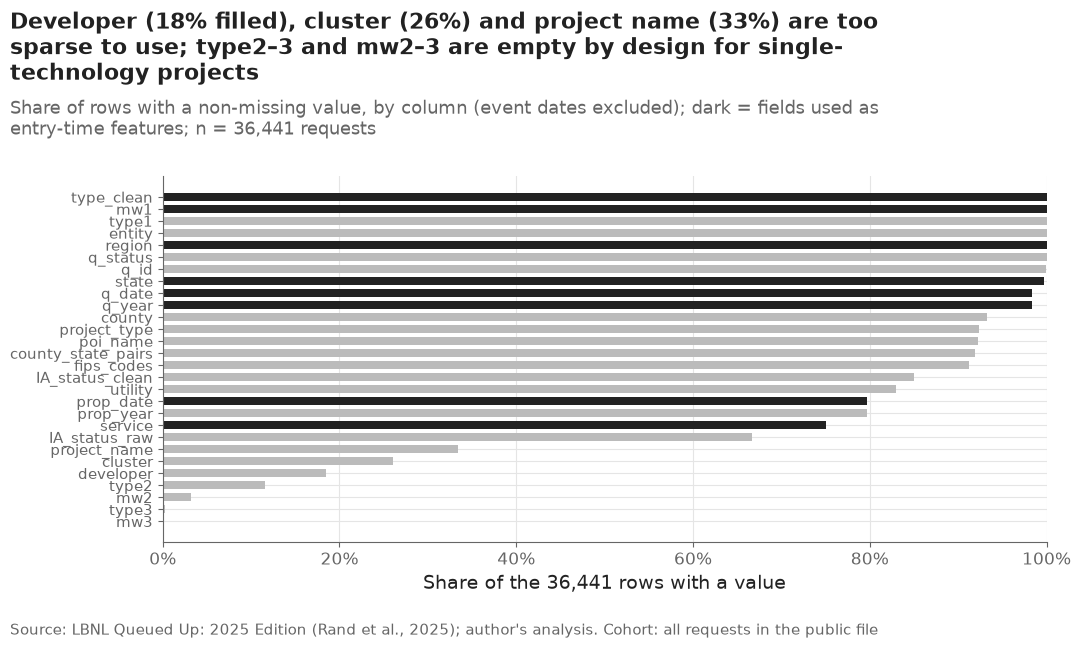

,mw3,type3,mw2,type2,developer,cluster,project_name,IA_status_raw,service,prop_year,prop_date,utility,IA_status_clean,fips_codes,county_state_pairs,poi_name,project_type,county,q_year,q_date,state,q_id,q_status,region,entity,type1,mw1,type_clean
share_filled,0.001,0.003,0.032,0.116,0.185,0.261,0.334,0.667,0.751,0.797,0.797,0.829,0.85,0.913,0.919,0.922,0.924,0.933,0.983,0.983,0.997,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [7]:
status_dates = ["on_date", "wd_date", "ia_date"]
completeness = raw.drop(columns=status_dates).notna().mean().sort_values()
feature_fields = {"q_date", "region", "state", "type_clean", "mw1", "service", "prop_date", "q_year"}

fig, ax = plt.subplots()
colors = [plots.INK if c in feature_fields else "#BBBBBB" for c in completeness.index]
ax.barh(completeness.index, completeness.values, color=colors, height=0.7)
ax.set_xlim(0, 1)
ax.set_xlabel("Share of the 36,441 rows with a value")
ax.tick_params(axis="y", labelsize=11)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
plots.finish(fig,
             f"Developer ({completeness['developer']:.0%} filled), cluster ({completeness['cluster']:.0%}) "
             f"and project name ({completeness['project_name']:.0%}) are too sparse to use; "
             "type2–3 and mw2–3 are empty by design for single-technology projects",
             "Share of rows with a non-missing value, by column (event dates excluded); "
             "dark = fields used as entry-time features; n = 36,441 requests",
             "all requests in the public file")
save(fig, "01_01_column_completeness",
     "Share of the 36,441 LBNL queue rows with a value in each column; status-specific "
     "event dates are excluded and shown in 01_02.")
plt.show()
completeness.round(3).to_frame("share_filled").T

**Reading this.** Developer (18.5% filled), cluster (26.1%) and project name (33.4%) are mostly empty, which is why rule R8 keeps them out of the models. `type2`, `type3`, `mw2` and `mw3` are empty by design: only hybrids have a second resource. The fields the entry-time features need (dark bars) are well filled, with two exceptions that will need a "missing" level or flag in notebook 04: `service` (75.1%) and the proposed online date (79.7%). For a developer or lender this sets the scope plainly: the model can only use what nearly every request reports — where, what, how big and when.

### 3.4 Event-date coverage by region — why three ISOs define Track A

A time-to-event model needs both ends of the clock. Dates are converted from
Excel serials; the 1970-01-01 placeholder counts as missing. The table goes
to `results/event_date_coverage.csv`.

In [8]:
dated = audit_queue.with_dates(raw)
dated["tech_group"] = dated["type_clean"].map(plots.tech_group)
coverage = audit_queue.event_date_coverage(dated)
coverage.to_csv(paths.RESULTS / "event_date_coverage.csv", index=False)

shares = coverage.set_index("region")[["q_date_share", "on_date_share", "wd_date_share"]]
(100 * shares).round(1)

,q_date_share,on_date_share,wd_date_share
region,,,
ERCOT,91.8,98.4,100.0
PJM,99.7,97.8,96.9
CAISO,99.8,95.2,82.6
MISO,99.7,1.4,41.8
SPP,98.7,4.9,0.0
NYISO,99.9,0.9,0.0
ISO-NE,99.3,4.1,97.9
West,97.8,21.5,7.5
Southeast,92.8,57.4,33.7


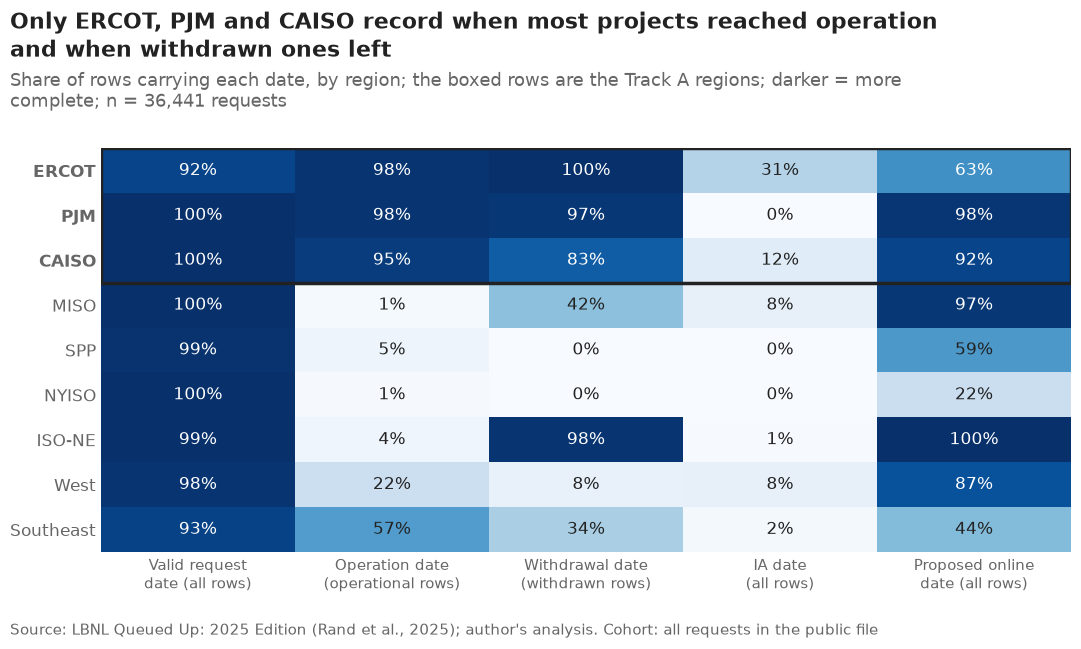

In [9]:
by_region = dated.groupby("region")
heat = pd.DataFrame({
    "Valid request\ndate (all rows)": coverage.set_index("region")["q_date_share"],
    "Operation date\n(operational rows)": coverage.set_index("region")["on_date_share"],
    "Withdrawal date\n(withdrawn rows)": coverage.set_index("region")["wd_date_share"],
    "IA date\n(all rows)": by_region["ia_date"].apply(lambda s: s.notna().mean()),
    "Proposed online\ndate (all rows)": by_region["prop_date"].apply(lambda s: s.notna().mean()),
}).reindex(config.ALL_REGIONS)

fig, ax = plt.subplots()
ax.imshow(heat.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns, fontsize=11)
ax.set_yticks(range(heat.shape[0]), heat.index)
ax.tick_params(length=0)
ax.grid(False)
for side in ax.spines.values():
    side.set_visible(False)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        value = heat.iat[i, j]
        ax.text(j, i, f"{value:.0%}", ha="center", va="center", fontsize=12,
                color="white" if value > 0.6 else plots.INK)
ax.add_patch(Rectangle((-0.5, -0.5), heat.shape[1], len(TRACK_A), fill=False,
                       edgecolor=plots.INK, linewidth=2.5))
for label in ax.get_yticklabels():
    if label.get_text() in TRACK_A:
        label.set_fontweight("bold")
both = [r for r in config.ALL_REGIONS
        if coverage.set_index("region").loc[r, "on_date_share"] >= 0.9
        and coverage.set_index("region").loc[r, "wd_date_share"] >= 0.8]
plots.finish(fig,
             f"Only {', '.join(both[:-1])} and {both[-1]} record when most projects "
             "reached operation and when withdrawn ones left",
             "Share of rows carrying each date, by region; the boxed rows are the Track A regions; "
             "darker = more complete; n = 36,441 requests",
             "all requests in the public file")
save(fig, "01_02_event_date_coverage",
     "Share of LBNL queue rows carrying each date field, by region. Operation and withdrawal "
     "dates are measured among operational and withdrawn rows respectively.")
plt.show()

**Reading this.** The three boxed ISOs are the only regions where both ends of the clock are recorded for most projects: operation dates for 95.2–98.4% of operational rows and withdrawal dates for 82.6–100% of withdrawn rows. Everywhere else one end is missing: MISO records an operation date for 1.4% of its operational rows, SPP and NYISO record no withdrawal dates at all, and the West has 21.5% and 7.5%. This is why the timing model (Track A) uses only CAISO, ERCOT and PJM and the other six regions enter only the all-regions "ever built?" model (Track B, decision #6). CAISO's withdrawal-date coverage (82.6%) is the weakest of the three; it failed the plan's original 83% bar, which Alan then set to 82% (decision #15). ERCOT has the weakest request-date coverage (91.8%). Interconnection-agreement dates are sparse everywhere; that does not matter for the main models because they are post-entry information (decision #7). Caveat: this is coverage of the *public* file — LBNL's report draws on some non-public data.

### 3.5 How the queue grew

Requests per year by region (small multiples, shared scale so panel heights
compare volumes), then requested capacity per year by technology.

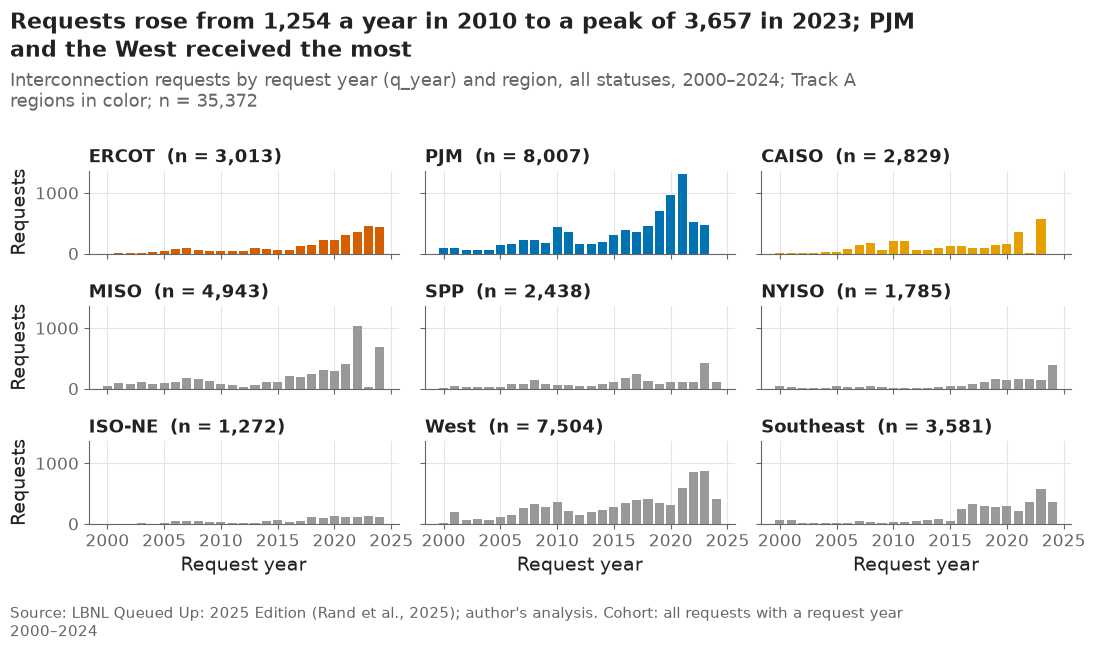

q_year,2010,2015,2019,2020,2021,2022,2023,2024
requests,1254,1123,2328,2622,3565,3525,3657,2493


In [10]:
years = range(2000, 2025)
per_year = (dated[dated["q_year"].between(2000, 2024)]
            .groupby(["q_year", "region"]).size().unstack().reindex(years).fillna(0))
national = per_year.sum(axis=1)

fig, axes = plt.subplots(3, 3, sharex=True, sharey=True)
for ax, region in zip(axes.flat, config.ALL_REGIONS):
    ax.bar(per_year.index, per_year[region], color=plots.region_color(region), width=0.8)
    ax.set_title(f"{region}  (n = {int(per_year[region].sum()):,})", fontsize=13)
for ax in axes[:, 0]:
    ax.set_ylabel("Requests")
for ax in axes[-1]:
    ax.set_xlabel("Request year")
peak = int(national.idxmax())
top_two = per_year.sum().sort_values(ascending=False).index[:2]
plots.finish(fig,
             f"Requests rose from {int(national[2010]):,} a year in 2010 to a peak of "
             f"{int(national.max()):,} in {peak}; {region_name(top_two[0])} and {region_name(top_two[1])} "
             "received the most",
             "Interconnection requests by request year (q_year) and region, all statuses, 2000–2024; "
             "Track A regions in color; n = " + f"{int(national.sum()):,}",
             "all requests with a request year 2000–2024")
save(fig, "01_03_requests_by_year_region",
     "Number of interconnection requests per year by region, 2000–2024, all statuses.")
plt.show()
national.loc[[2010, 2015, 2019, 2020, 2021, 2022, 2023, 2024]].astype(int).to_frame("requests").T

**Reading this.** National requests rose from 1,254 in 2010 to a peak of 3,657 in 2023 and fell to 2,493 in 2024. PJM (8,007 requests since 2000) and the West (7,504) received the most. The panels are not smooth trends: CAISO has no bar in 2022 or 2024 and MISO's 2023 bar is almost empty, which looks like requests being accepted in periodic windows rather than continuously. I have not yet checked this against each ISO's queue rules, so the report will not lean on it until I do. For the models it means request year acts as a cohort marker with jumps, not as a smooth time trend.

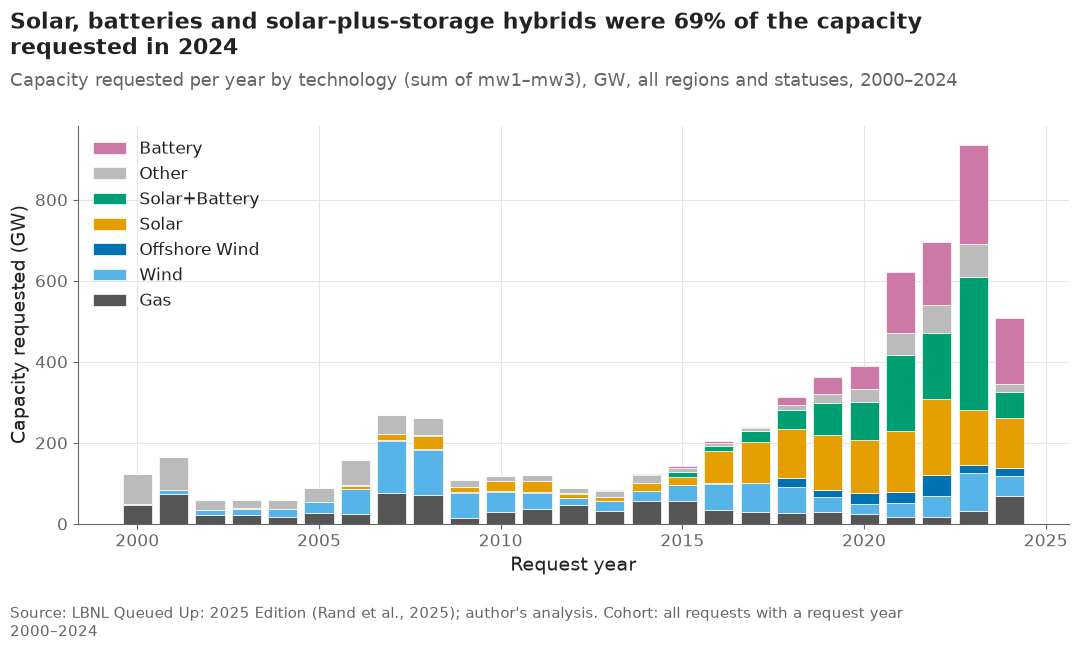

tech_group,Gas,Wind,Offshore Wind,Solar,Solar+Battery,Other,Battery
q_year,,,,,,,
2015,55.0,40.0,0.0,21.0,11.0,10.0,6.0
2020,25.0,25.0,27.0,130.0,94.0,32.0,57.0
2022,18.0,51.0,51.0,189.0,163.0,68.0,156.0
2023,32.0,92.0,21.0,134.0,329.0,83.0,245.0
2024,70.0,47.0,21.0,124.0,63.0,19.0,163.0


In [11]:
stack_order = ["Gas", "Wind", "Offshore Wind", "Solar", "Solar+Battery", "Other", "Battery"]
cap = (dated[dated["q_year"].between(2000, 2024)]
       .groupby(["q_year", "tech_group"])["mw"].sum().unstack()
       .reindex(index=years, columns=stack_order).fillna(0) / 1000)

fig, ax = plt.subplots()
bottom = np.zeros(len(cap))
for group in stack_order:
    ax.bar(cap.index, cap[group], bottom=bottom, color=config.TECH_COLORS[group], width=0.8,
           label=group, edgecolor="white", linewidth=0.5)
    bottom += cap[group].values
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="upper left")
ax.set_xlabel("Request year")
ax.set_ylabel("Capacity requested (GW)")
clean_share = cap.loc[2024, ["Solar", "Solar+Battery", "Battery"]].sum() / cap.loc[2024].sum()
plots.finish(fig,
             f"Solar, batteries and solar-plus-storage hybrids were {clean_share:.0%} of the "
             f"capacity requested in 2024",
             "Capacity requested per year by technology (sum of mw1–mw3), GW, all regions and statuses, "
             "2000–2024",
             "all requests with a request year 2000–2024")
save(fig, "01_04_capacity_by_year_technology",
     "Capacity requested per year by technology group (GW), all regions, 2000–2024.")
plt.show()
cap.loc[[2015, 2020, 2022, 2023, 2024]].round(0)

**Reading this.** The technology mix of the queue changed completely inside the study period. In 2015 gas was the largest group (55 GW requested); by 2023 solar+battery hybrids alone were 329 GW and standalone batteries 245 GW, while gas fell to 25 GW in 2020 and 18 GW in 2022 before rebounding to 70 GW in 2024. Two consequences: technology effects have to be allowed to differ by entry cohort, and most storage requests are recent, so their outcomes are still largely unobserved (censored) — the model will know much less about batteries than about wind.

### 3.6 How requests end

Status mix by region (share of projects), then the outcome of each request
year by capacity. The second figure reproduces LBNL's headline: of capacity
requested in 2000–2019, about 13% reached operation and 77% was withdrawn.

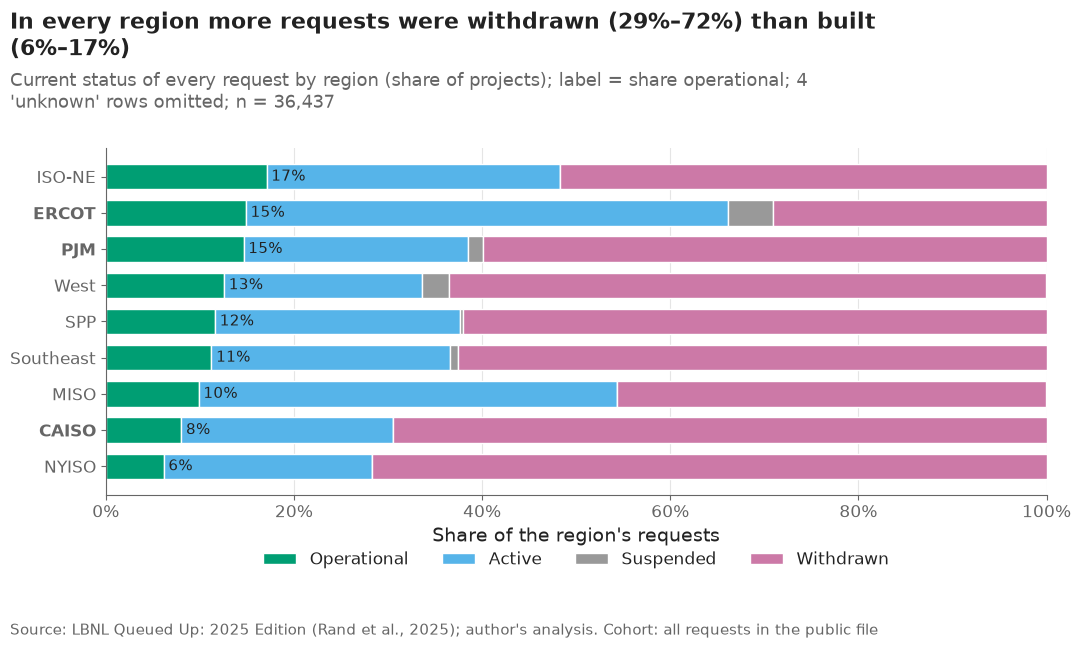

q_status,operational,active,suspended,withdrawn
region,,,,
NYISO,6.2,22.1,0.0,71.7
CAISO,8.0,22.5,0.0,69.5
MISO,9.9,44.5,0.0,45.6
Southeast,11.2,25.4,0.9,62.5
SPP,11.6,26.0,0.3,62.0
West,12.6,21.1,2.8,63.5
PJM,14.7,23.8,1.6,59.9
ERCOT,14.9,51.2,4.8,29.1
ISO-NE,17.1,31.1,0.0,51.8


In [12]:
statuses = ["operational", "active", "suspended", "withdrawn"]
mix = (pd.crosstab(dated["region"], dated["q_status"], normalize="index")
       .reindex(index=config.ALL_REGIONS, columns=statuses).fillna(0)
       .sort_values("operational"))

fig, ax = plt.subplots()
left = np.zeros(len(mix))
for status in statuses:
    ax.barh(mix.index, mix[status], left=left, color=config.STATUS_COLORS[status], height=0.7,
            label=status.capitalize(), edgecolor="white", linewidth=1)
    left += mix[status].values
for i, region in enumerate(mix.index):
    ax.text(mix.loc[region, "operational"] + 0.005, i, f"{mix.loc[region, 'operational']:.0%}",
            va="center", ha="left", fontsize=11, color=plots.INK)
for label in ax.get_yticklabels():
    if label.get_text() in TRACK_A:
        label.set_fontweight("bold")
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Share of the region's requests")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plots.finish(fig,
             f"In every region more requests were withdrawn ({mix['withdrawn'].min():.0%}–"
             f"{mix['withdrawn'].max():.0%}) than built ({mix['operational'].min():.0%}–"
             f"{mix['operational'].max():.0%})",
             "Current status of every request by region (share of projects); label = share operational; "
             "4 'unknown' rows omitted; n = 36,437",
             "all requests in the public file")
save(fig, "01_05_status_mix_by_region",
     "Share of requests in each current status (operational, active, suspended, withdrawn) by region.")
plt.show()
(100 * mix).round(1)

**Reading this.** In every region more requests were withdrawn than built: from 29.1% withdrawn against 14.9% operational in ERCOT to 71.7% against 6.2% in NYISO. ERCOT stands out for how much is still open — 51.2% of its requests are active and 4.8% suspended. Among the Track A regions CAISO completes the smallest share (8.0%). These shares pool old, resolved cohorts with recent ones that have had no time to finish, so they understate eventual completion for recent entrants; the survival curves in notebook 03 separate the two. The 4 "unknown" rows are left out.

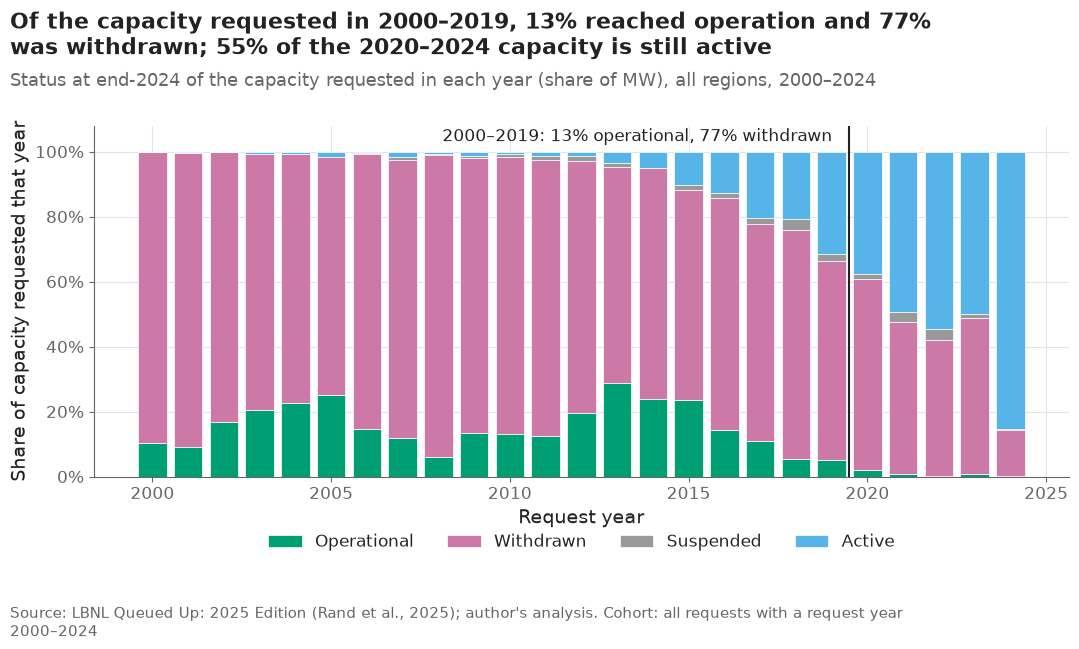

Capacity requested in 2020–2024 that is still active: 55.1%


,q_status,gw,share
0,active,294.383,0.094
1,operational,394.767,0.126
2,suspended,36.758,0.012
3,unknown,0.107,0.000
4,withdrawn,2417.956,0.769


In [13]:
headline = audit_queue.capacity_shares_by_status(dated)
op_share = headline.set_index("q_status").loc["operational", "share"]
wd_share = headline.set_index("q_status").loc["withdrawn", "share"]

by_year = (dated[dated["q_year"].between(2000, 2024)]
           .pivot_table(index="q_year", columns="q_status", values="mw", aggfunc="sum")
           .reindex(index=years, columns=["operational", "withdrawn", "suspended", "active"]).fillna(0))
by_year = by_year.div(by_year.sum(axis=1), axis=0)

fig, ax = plt.subplots()
bottom = np.zeros(len(by_year))
for status in by_year.columns:
    ax.bar(by_year.index, by_year[status], bottom=bottom, color=config.STATUS_COLORS[status],
           width=0.8, label=status.capitalize(), edgecolor="white", linewidth=0.5)
    bottom += by_year[status].values
ax.axvline(2019.5, color=plots.INK, linewidth=1.5)
ax.text(2019.3, 1.02, f"2000–2019: {op_share:.0%} operational, {wd_share:.0%} withdrawn  ",
        ha="right", va="bottom", fontsize=12)
ax.set_ylim(0, 1.08)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_ylabel("Share of capacity requested that year")
ax.set_xlabel("Request year")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
recent_cap = dated[dated["q_year"].between(2020, 2024)]
active_recent = recent_cap.loc[recent_cap["q_status"] == "active", "mw"].sum() / recent_cap["mw"].sum()
plots.finish(fig,
             f"Of the capacity requested in 2000–2019, {op_share:.0%} reached operation and "
             f"{wd_share:.0%} was withdrawn; {active_recent:.0%} of the 2020–2024 capacity is still active",
             "Status at end-2024 of the capacity requested in each year (share of MW), all regions, "
             "2000–2024",
             "all requests with a request year 2000–2024")
save(fig, "01_06_outcome_by_request_year",
     "Share of each request year's capacity that is operational, withdrawn, suspended or still "
     "active at the end of 2024.")
plt.show()
print(f"Capacity requested in 2020–2024 that is still active: {pct(active_recent)}")
headline.round(3)

**Reading this.** This reproduces the LBNL headline from the public file: of the capacity requested in 2000–2019, 12.6% is operational and 76.9% was withdrawn (by MW), against the ≈13% and ≈77% published by Rand et al. (2025). The right-hand bars show why the project needs a time-to-event model rather than a classifier on final status: 55.1% of the capacity requested in 2020–2024 is still active, so its outcome is not known yet (right-censored), and treating it as "not built" would be wrong.

### 3.7 How long it takes to be built

Years from request to commercial operation for completed projects, by the
year they came online (LBNL's "IR to COD" measure), then the same median for
the three Track A regions.

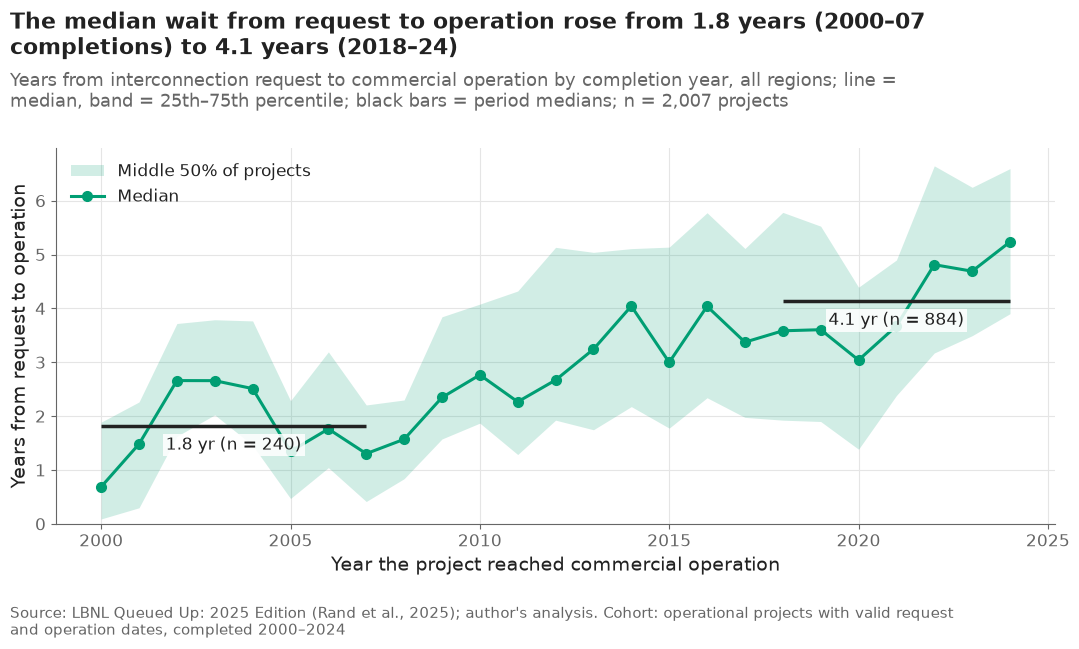

cod_year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
n,10.00,20.00,26.00,21.00,27.00,25.00,52.00,59.00,76.00,55.00,73.00,84.00,93.00,70.00,80.00,123.00,128.00,101.00,101.00,90.00,134.00,150.00,102.00,138.00,169.00
median,0.69,1.48,2.66,2.66,2.51,1.34,1.76,1.30,1.57,2.35,2.77,2.27,2.67,3.24,4.04,3.00,4.04,3.37,3.58,3.60,3.04,3.67,4.81,4.69,5.23
q25,0.09,0.30,1.63,2.02,1.46,0.47,1.04,0.41,0.84,1.58,1.87,1.29,1.92,1.75,2.18,1.78,2.34,1.98,1.92,1.90,1.39,2.38,3.17,3.49,3.90
q75,1.89,2.26,3.72,3.79,3.77,2.29,3.19,2.21,2.30,3.84,4.08,4.32,5.13,5.04,5.11,5.14,5.78,5.11,5.78,5.53,4.39,4.90,6.65,6.25,6.60


In [14]:
ir = audit_queue.ir_to_cod_years(dated)
cod = (ir[ir["cod_year"].between(2000, 2024)].groupby("cod_year")["years"]
       .agg(n="size", median="median", q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75)))
cod.to_csv(paths.RESULTS / "ir_to_cod_by_year.csv")
early = ir.loc[ir["cod_year"].between(2000, 2007), "years"]
late = ir.loc[ir["cod_year"].between(2018, 2024), "years"]

fig, ax = plt.subplots()
ax.fill_between(cod.index, cod["q25"], cod["q75"], color=config.OUTCOME_COLORS["operation"],
                alpha=0.18, linewidth=0, label="Middle 50% of projects")
ax.plot(cod.index, cod["median"], color=config.OUTCOME_COLORS["operation"], marker="o",
        label="Median")
for span, values in [((2000, 2007), early), ((2018, 2024), late)]:
    ax.hlines(values.median(), *span, color=plots.INK, linewidth=2.5)
    ax.text(np.mean(span), values.median() - 0.2, f"{values.median():.1f} yr (n = {len(values):,})",
            ha="center", va="top", fontsize=12,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85, "pad": 2})
ax.set_xlabel("Year the project reached commercial operation")
ax.set_ylabel("Years from request to operation")
ax.set_ylim(0, None)
ax.legend(loc="upper left")
plots.finish(fig,
             f"The median wait from request to operation rose from {early.median():.1f} years "
             f"(2000–07 completions) to {late.median():.1f} years (2018–24)",
             "Years from interconnection request to commercial operation by completion year, all regions; "
             "line = median, band = 25th–75th percentile; black bars = period medians; "
             f"n = {int(cod['n'].sum()):,} projects",
             "operational projects with valid request and operation dates, completed 2000–2024")
save(fig, "01_07_ir_to_cod_by_year",
     "Median and interquartile range of years from interconnection request to commercial operation, "
     "by year of operation, all regions.")
plt.show()
cod.round(2).T

**Reading this.** The median time from request to commercial operation went from 1.82 years for projects completed in 2000–07 (n = 240) to 4.14 years for those completed in 2018–24 (n = 884), which reproduces LBNL's "more than doubled, to over four years". The upper quartile reached 6.65 years for 2022 completions. Two caveats: this looks only at projects that finished, so slow projects still waiting are missing (survivorship), and it pools all regions, but operation dates exist mainly in the three Track A ISOs (01_02), so it is dominated by them.

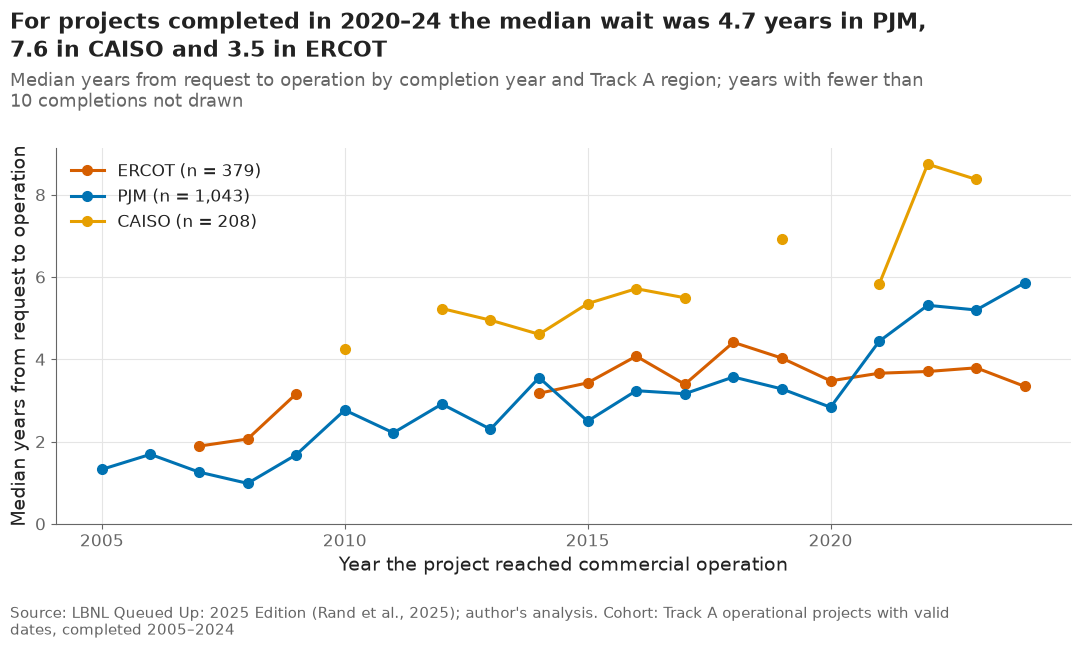

,ERCOT,PJM,CAISO
"median years, completed 2020–24",3.54,4.72,7.59


In [15]:
recent = {}
fig, ax = plt.subplots()
for region in TRACK_A:
    part = ir[(ir["region"] == region) & ir["cod_year"].between(2005, 2024)]
    series = part.groupby("cod_year")["years"].agg(["median", "size"]).reindex(range(2005, 2025))
    # medians of fewer than 10 projects are too noisy to plot; the gap is left visible
    series.loc[~(series["size"] >= 10), "median"] = np.nan
    ax.plot(series.index, series["median"], color=plots.region_color(region), marker="o",
            label=f"{region} (n = {len(part):,})")
    recent[region] = part.loc[part["cod_year"].between(2020, 2024), "years"].median()
year_ticks(ax, 2005, 2024)
ax.set_xlabel("Year the project reached commercial operation")
ax.set_ylabel("Median years from request to operation")
ax.set_ylim(0, None)
ax.legend(loc="upper left")
plots.finish(fig,
             f"For projects completed in 2020–24 the median wait was {recent['PJM']:.1f} years in PJM, "
             f"{recent['CAISO']:.1f} in CAISO and {recent['ERCOT']:.1f} in ERCOT",
             "Median years from request to operation by completion year and Track A region; "
             "years with fewer than 10 completions not drawn",
             "Track A operational projects with valid dates, completed 2005–2024")
save(fig, "01_08_ir_to_cod_by_region",
     "Median years from request to commercial operation by completion year for CAISO, ERCOT and PJM.")
plt.show()
pd.Series(recent, name="median years, completed 2020–24").round(2).to_frame().T

**Reading this.** For projects completed in 2020–24 the median wait was 7.59 years in CAISO, 4.72 in PJM and 3.54 in ERCOT. ERCOT's median has stayed in a narrow band since 2014 while PJM's climbed after 2020, and CAISO's has been the longest throughout. For a lender this is the practical point: the region alone moves a realistic COD assumption by about four years, so a single national figure is not a usable assumption. The survivorship caveat of 01_07 applies, and CAISO's yearly medians rest on few projects (gaps mark years with fewer than 10 completions).

### 3.8 The naive mock-up: five-year completion by region

Share of 2010–2018 generation entrants that reached operation within five
years of their request, with 95% Wilson intervals. This is the "cohort
average" a developer would use today, and the plan expects CAISO ≈ 4%,
ERCOT ≈ 21%, PJM ≈ 15%.

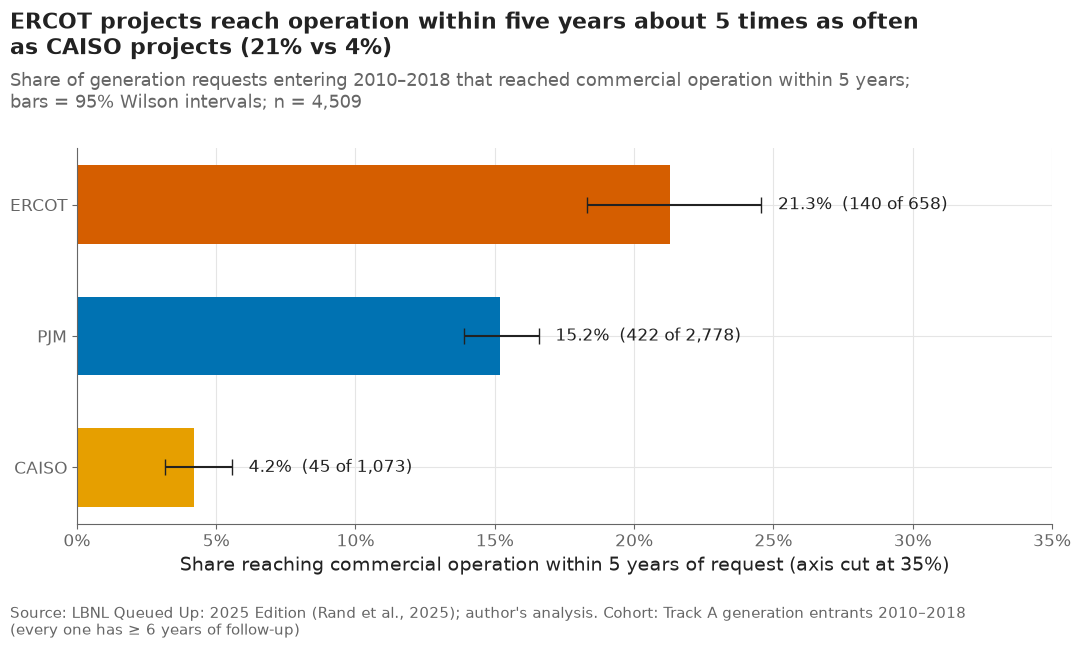

,region,n,completed,share,ci_low,ci_high
0,ERCOT,658,140,0.2128,0.1832,0.2457
1,PJM,2778,422,0.1519,0.1390,0.1657
2,CAISO,1073,45,0.0419,0.0315,0.0557


In [16]:
mock = audit_queue.five_year_completion(dated)
mock.to_csv(paths.RESULTS / "naive_mockup.csv", index=False)
mock_shares = mock.set_index("region")["share"]

fig, ax = plt.subplots()
order = mock.sort_values("share")
for i, row in enumerate(order.itertuples()):
    ax.barh(i, row.share, color=plots.region_color(row.region), height=0.6)
    ax.errorbar(row.share, i, xerr=[[row.share - row.ci_low], [row.ci_high - row.share]],
                color=plots.INK, capsize=6, linewidth=1.5)
    ax.text(row.ci_high + 0.006, i, f"{row.share:.1%}  ({row.completed} of {row.n:,})",
            va="center", fontsize=12)
ax.set_yticks(range(len(order)), order["region"])
ax.set_xlim(0, 0.35)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Share reaching commercial operation within 5 years of request (axis cut at 35%)")
ratio = mock_shares["ERCOT"] / mock_shares["CAISO"]
plots.finish(fig,
             f"ERCOT projects reach operation within five years about {ratio:.0f} times as often as "
             f"CAISO projects ({mock_shares['ERCOT']:.0%} vs {mock_shares['CAISO']:.0%})",
             "Share of generation requests entering 2010–2018 that reached commercial operation within "
             f"5 years; bars = 95% Wilson intervals; n = {mock['n'].sum():,}",
             "Track A generation entrants 2010–2018 (every one has ≥ 6 years of follow-up)")
save(fig, "01_09_naive_five_year_completion",
     "Naive five-year completion share for 2010–2018 generation entrants in CAISO, ERCOT and PJM, "
     "with 95% Wilson intervals.")
plt.show()
mock.round(4)

**Reading this.** Of the 2010–2018 generation entrants, 21.3% reached operation within five years in ERCOT (140 of 658), 15.2% in PJM (422 of 2,778) and 4.2% in CAISO (45 of 1,073); the 95% intervals do not overlap. This reproduces the plan's 21% / 15% / 4% to within 0.3 points. It is the simplest version of the baseline the models must beat and already shows why a national average would be a straw man. Every entrant in this window has at least six years of follow-up before the censor date, so the naive share is not biased by censoring at five years. The real baseline in notebook 05 is finer (region × technology).

### 3.9 The Track A sample and the held-out test cohort

How many projects can enter the three-ISO timing model, and how many events
the 2017–2019 test cohort holds by the censor date (2024-12-31).

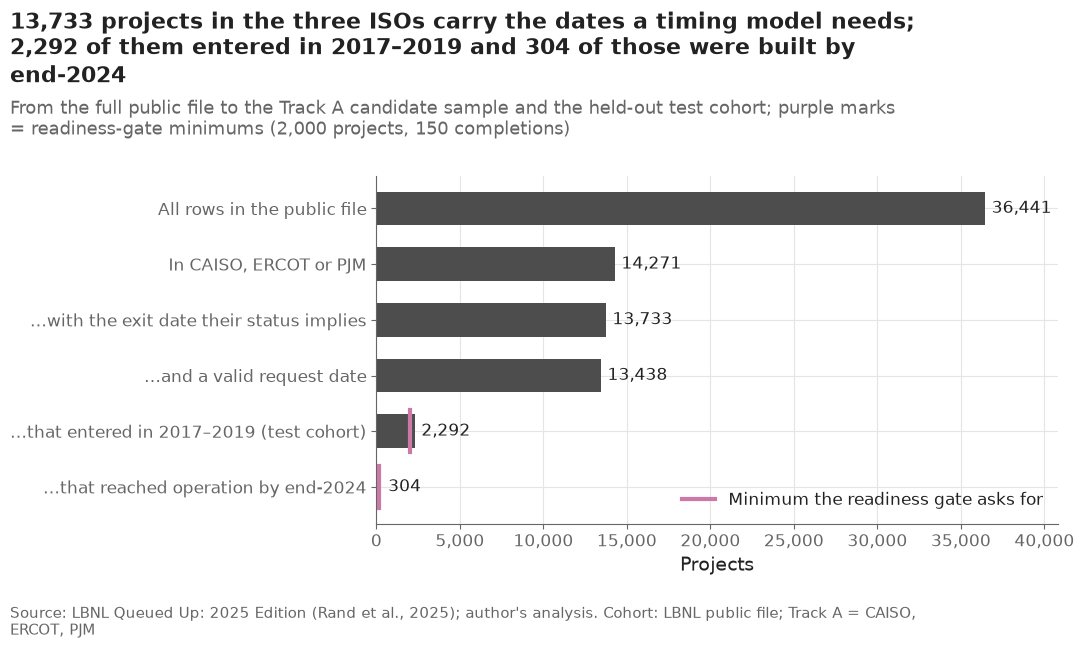

{'projects': 2292, 'completions': 304, 'withdrawals': 1358}
All Track A rows entering 2017–2019, whatever their dates: 2313


excluded rows
region q_status                  
CAISO  operational             11
       withdrawn              342
ERCOT  operational              8
PJM    operational             26
       withdrawn              151

In [17]:
in_region = dated["region"].isin(TRACK_A)
candidates = audit_queue.track_a_candidates(dated)
held_out = audit_queue.held_out_cohort_events(dated, candidates)
steps = pd.Series({
    "All rows in the public file": len(dated),
    "In CAISO, ERCOT or PJM": int(in_region.sum()),
    "…with the exit date their status implies": int(candidates.sum()),
    "…and a valid request date": int((candidates & dated["q_date_valid"]).sum()),
    "…that entered in 2017–2019 (test cohort)": held_out["projects"],
    "…that reached operation by end-2024": held_out["completions"],
})
excluded = (in_region & ~candidates)
exclusions = dated[excluded].groupby(["region", "q_status"]).size().rename("excluded rows")

fig, ax = plt.subplots()
ypos = np.arange(len(steps))[::-1]
ax.barh(ypos, steps.values, color="#4D4D4D", height=0.6)
minimums = {4: config.TEST_MIN_PROJECTS, 5: config.TEST_MIN_COMPLETIONS}
for i, (y, value) in enumerate(zip(ypos, steps.values)):
    ax.text(max(value, minimums.get(i, 0)) + 400, y, f"{value:,}", va="center", fontsize=12)
for i, minimum in minimums.items():
    ax.plot([minimum, minimum], [ypos[i] - 0.38, ypos[i] + 0.38],
            color=config.OUTCOME_COLORS["withdrawal"], linewidth=3)
ax.set_yticks(ypos, steps.index)
ax.set_xlim(0, len(dated) * 1.12)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:,.0f}")
ax.set_xlabel("Projects")
ax.legend(handles=[Line2D([], [], color=config.OUTCOME_COLORS["withdrawal"], linewidth=3,
                          label="Minimum the readiness gate asks for")], loc="lower right")
plots.finish(fig,
             f"{steps.iloc[2]:,} projects in the three ISOs carry the dates a timing model needs; "
             f"{held_out['projects']:,} of them entered in 2017–2019 and {held_out['completions']} "
             "of those were built by end-2024",
             "From the full public file to the Track A candidate sample and the held-out test cohort; "
             f"purple marks = readiness-gate minimums ({config.TEST_MIN_PROJECTS:,} projects, "
             f"{config.TEST_MIN_COMPLETIONS} completions)",
             "LBNL public file; Track A = CAISO, ERCOT, PJM")
save(fig, "01_10_track_a_sample_flow",
     "Row counts from the full public file to the Track A candidate sample and the 2017–2019 test "
     "cohort, with the readiness-gate minimums.")
plt.show()
print(held_out)
print("All Track A rows entering 2017–2019, whatever their dates:",
      int((in_region & dated["q_date"].dt.year.between(*config.TEST_YEARS)).sum()))
exclusions.to_frame()

**Reading this.** 13,733 projects in the three ISOs carry the exit date their status implies (inside the expected 13,500–14,500); 13,438 of them also have a valid request date, which notebook 04 needs. The exclusions are concentrated in CAISO (342 withdrawn rows without a withdrawal date, 11 operational rows without an operation date) and PJM (151 and 26); ERCOT loses 8 operational rows. The 2017–2019 test cohort holds 2,292 projects with 304 completions and 1,358 withdrawals by the end of 2024. The 304 completions are twice the 150 the gate asks for. The plan's original minimum of 2,500 projects could not be met by any definition of the sample — the three ISOs contain only 2,313 rows that entered in 2017–2019 at all — so Alan lowered it to 2,000 after the first evaluation (decision #15).

### 3.10 More of the first look

Six more views that later notebooks build on: project size (the FERC 20 MW
step), what is still waiting, how fast withdrawn projects leave, developers'
proposed timelines, how late completed projects were, and the rise of
hybrids.

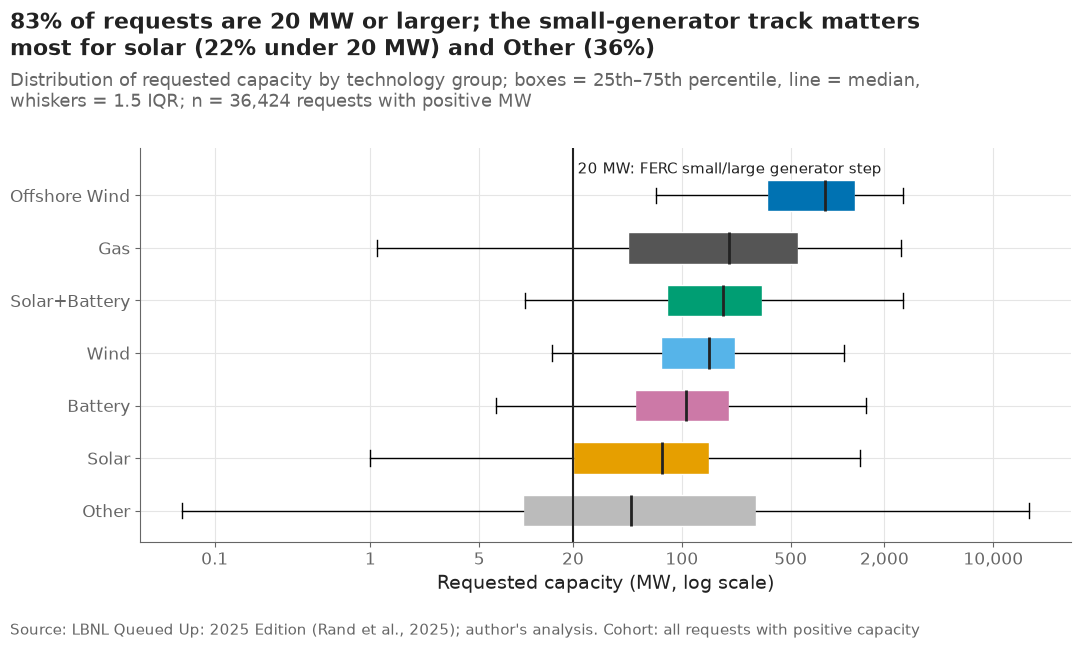

tech_group,Battery,Gas,Offshore Wind,Other,Solar,Solar+Battery,Wind
share >= 20 MW,0.908,0.843,0.953,0.637,0.777,0.92,0.904


In [18]:
sized = dated[dated["mw"] > 0]
groups = sized.groupby("tech_group")["mw"].median().sort_values().index
large_share = (sized["mw"] >= config.FERC_SIZE_STEP_MW).groupby(sized["tech_group"]).mean()

fig, ax = plt.subplots()
box = ax.boxplot([np.log10(sized.loc[sized["tech_group"] == g, "mw"]) for g in groups],
                 orientation="horizontal", tick_labels=groups, showfliers=False, widths=0.6,
                 patch_artist=True, medianprops={"color": plots.INK, "linewidth": 2})
for patch, group in zip(box["boxes"], groups):
    patch.set_facecolor(config.TECH_COLORS[group])
    patch.set_edgecolor("white")
ax.axvline(np.log10(config.FERC_SIZE_STEP_MW), color=plots.INK, linewidth=1.5)
ax.text(np.log10(config.FERC_SIZE_STEP_MW) + 0.03, len(groups) + 0.35,
        "20 MW: FERC small/large generator step", fontsize=11, va="bottom")
ticks = [0.1, 1, 5, 20, 100, 500, 2000, 10000]
ax.set_xticks(np.log10(ticks), [f"{t:,}" for t in ticks])
ax.set_xlabel("Requested capacity (MW, log scale)")
ax.set_ylim(0.4, len(groups) + 0.9)
small_share = 1 - large_share
plots.finish(fig,
             f"{(sized['mw'] >= 20).mean():.0%} of requests are 20 MW or larger; the small-generator "
             f"track matters most for solar ({small_share['Solar']:.0%} under 20 MW) and "
             f"Other ({small_share['Other']:.0%})",
             "Distribution of requested capacity by technology group; boxes = 25th–75th percentile, "
             f"line = median, whiskers = 1.5 IQR; n = {len(sized):,} requests with positive MW",
             "all requests with positive capacity")
save(fig, "01_11_size_by_technology",
     "Distribution of requested capacity (MW, log scale) by technology group with the 20 MW FERC "
     "small/large generator threshold.")
plt.show()
large_share.round(3).to_frame("share >= 20 MW").T

**Reading this.** 83% of requests are 20 MW or larger. The share at or above 20 MW is lowest for Other (63.7%) and solar (77.7%) and highest for offshore wind (95.3%). Solar's box starts exactly at 20 MW, a hint that requests bunch at the FERC small/large-generator threshold; F3 in notebook 03 will test whether completion actually changes at that step. The `size_regime` bins of notebook 04 are built around the same 20 MW line.

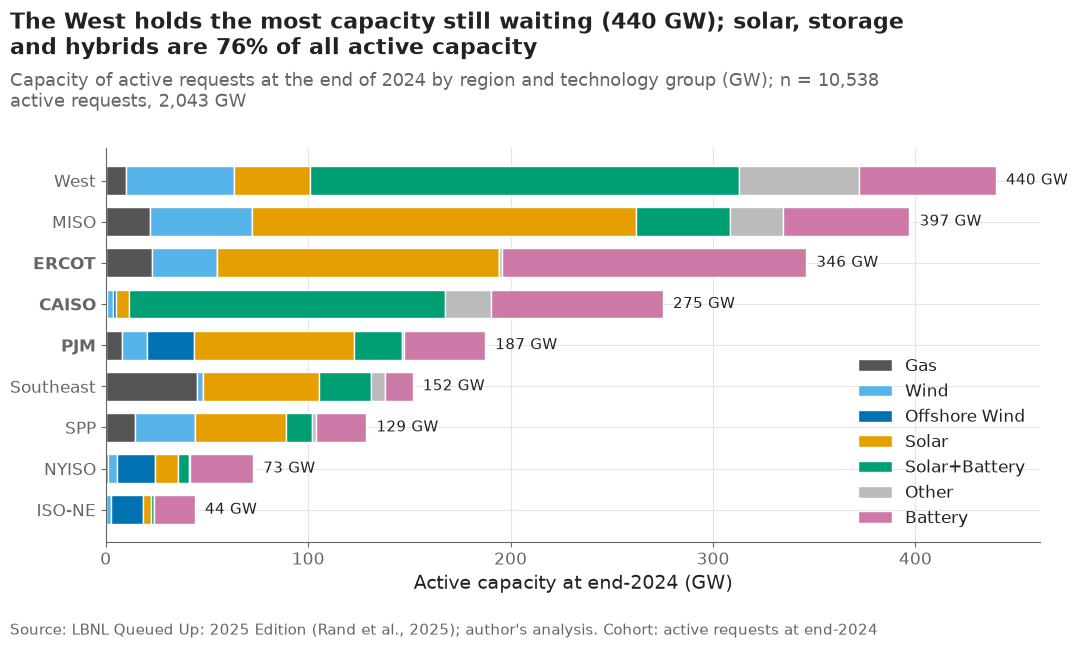

tech_group,Gas,Wind,Offshore Wind,Solar,Solar+Battery,Other,Battery
region,,,,,,,
ISO-NE,0.0,3.0,16.0,4.0,2.0,0.0,20.0
NYISO,1.0,4.0,19.0,12.0,5.0,0.0,31.0
SPP,14.0,30.0,0.0,45.0,12.0,2.0,25.0
Southeast,45.0,3.0,0.0,57.0,26.0,7.0,14.0
PJM,8.0,13.0,23.0,79.0,24.0,1.0,40.0
CAISO,1.0,3.0,1.0,7.0,156.0,22.0,85.0
ERCOT,23.0,32.0,0.0,139.0,0.0,1.0,150.0
MISO,22.0,50.0,0.0,190.0,47.0,26.0,63.0
West,10.0,53.0,0.0,38.0,212.0,59.0,67.0


In [19]:
active = dated[dated["q_status"] == "active"]
active_gw = (active.groupby(["region", "tech_group"])["mw"].sum().unstack()
             .reindex(columns=stack_order).fillna(0) / 1000)
active_gw = active_gw.loc[active_gw.sum(axis=1).sort_values().index]

fig, ax = plt.subplots()
left = np.zeros(len(active_gw))
for group in stack_order:
    ax.barh(active_gw.index, active_gw[group], left=left, color=config.TECH_COLORS[group],
            height=0.7, label=group, edgecolor="white", linewidth=1)
    left += active_gw[group].values
for i, total in enumerate(active_gw.sum(axis=1)):
    ax.text(total + 5, i, f"{total:,.0f} GW", va="center", fontsize=11)
for label in ax.get_yticklabels():
    if label.get_text() in TRACK_A:
        label.set_fontweight("bold")
ax.set_xlabel("Active capacity at end-2024 (GW)")
ax.legend(loc="lower right")
solar_storage = active_gw[["Solar", "Solar+Battery", "Battery"]].sum().sum() / active_gw.sum().sum()
plots.finish(fig,
             f"{region_name(active_gw.sum(axis=1).idxmax())[0].upper()}"
             f"{region_name(active_gw.sum(axis=1).idxmax())[1:]} holds the most capacity still waiting "
             f"({active_gw.sum(axis=1).max():,.0f} GW); solar, storage and hybrids are "
             f"{solar_storage:.0%} of all active capacity",
             "Capacity of active requests at the end of 2024 by region and technology group (GW); "
             f"n = {len(active):,} active requests, {active['mw'].sum() / 1000:,.0f} GW",
             "active requests at end-2024")
save(fig, "01_12_active_capacity_region_technology",
     "Capacity of requests still active at the end of 2024 by region and technology group (GW).")
plt.show()
active_gw.round(0)

**Reading this.** At the end of 2024 the public file holds 2,043 GW in 10,538 active requests (summed over all resource types, so hybrid storage counts on top of the generator; LBNL's report splits generation and storage differently). The West has the most (440 GW), and solar, storage and hybrids make up 76% of all active capacity. ERCOT shows 0.0 GW of solar+battery, which matches figure 01_16: ERCOT's queue in this file records no hybrids, presumably listing the solar and storage parts as separate requests. That makes the hybrid flag uninformative inside ERCOT.

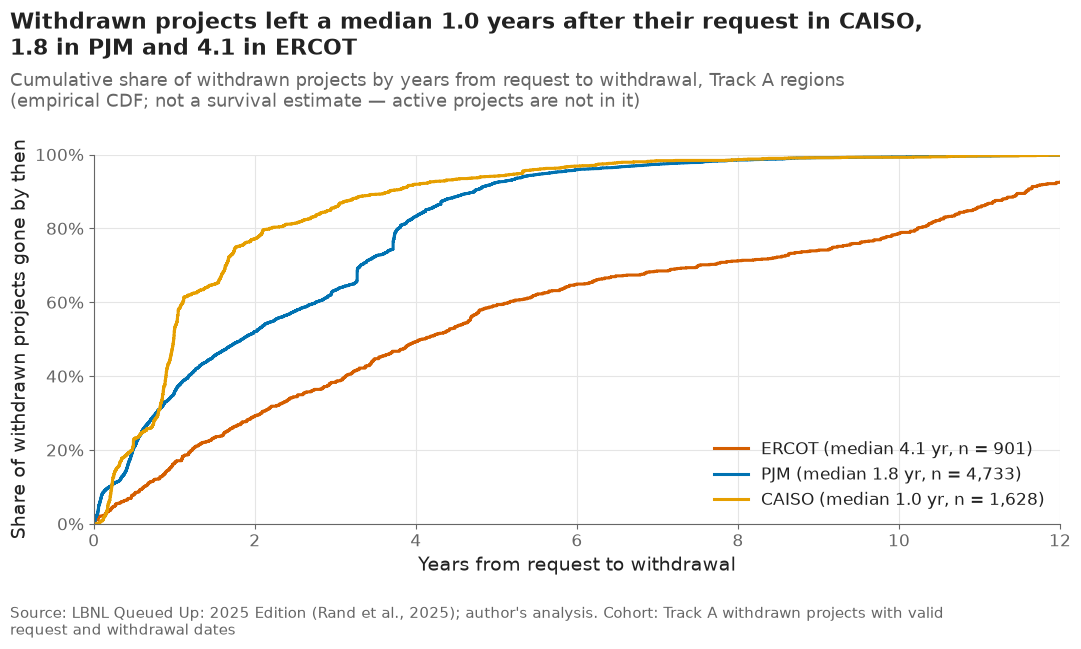

,count,mean,std,min,25%,50%,75%,max
region,,,,,,,,
CAISO,1628.0,1.59,1.73,0.0,0.62,0.99,1.77,13.49
ERCOT,901.0,5.27,4.18,0.0,1.66,4.08,9.24,20.14
PJM,4733.0,2.31,2.02,0.0,0.60,1.84,3.72,21.53


In [20]:
def ecdf(values):
    """Sorted values and their cumulative shares, for a step plot."""
    x = np.sort(np.asarray(values))
    return x, np.arange(1, len(x) + 1) / len(x)


wd = dated[(dated["q_status"] == "withdrawn") & in_region & dated["q_date_valid"]
           & dated["wd_date"].notna() & (dated["wd_date"] >= dated["q_date"])]
wd_years = (wd["wd_date"] - wd["q_date"]).dt.days / config.DAYS_PER_YEAR
wd_medians = wd_years.groupby(wd["region"]).median()

fig, ax = plt.subplots()
for region in TRACK_A:
    x, y = ecdf(wd_years[wd["region"] == region])
    ax.step(x, y, where="post", color=plots.region_color(region),
            label=f"{region} (median {wd_medians[region]:.1f} yr, n = {len(x):,})")
ax.set_xlim(0, 12)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xlabel("Years from request to withdrawal")
ax.set_ylabel("Share of withdrawn projects gone by then")
ax.legend(loc="lower right")
plots.finish(fig,
             f"Withdrawn projects left a median {wd_medians['CAISO']:.1f} years after their request in "
             f"CAISO, {wd_medians['PJM']:.1f} in PJM and {wd_medians['ERCOT']:.1f} in ERCOT",
             "Cumulative share of withdrawn projects by years from request to withdrawal, Track A regions "
             "(empirical CDF; not a survival estimate — active projects are not in it)",
             "Track A withdrawn projects with valid request and withdrawal dates")
save(fig, "01_13_time_to_withdrawal",
     "Empirical cumulative distribution of years from request to withdrawal for withdrawn projects in "
     "CAISO, ERCOT and PJM.")
plt.show()
wd_years.groupby(wd["region"]).describe().round(2)

**Reading this.** Withdrawn projects left a median 0.99 years after their request in CAISO, 1.84 in PJM and 4.08 in ERCOT; in ERCOT a quarter of them stayed more than 9.24 years before leaving. In CAISO and PJM, projects that fail tend to fail early (three quarters were gone within 1.77 and 3.72 years). PJM's curve has visible steps between three and four years — many projects leaving at once — which a discrete-time model with a free year-in-queue effect can represent better than a smooth hazard. This is not a survival estimate: it only describes projects that did withdraw. Notebook 03 estimates the cumulative incidence of withdrawal properly, with active projects censored. **Correction from notebook 03:** 441 of ERCOT's withdrawals share one recorded date, 2018-08-29, and none is dated earlier, so ERCOT's long times to withdrawal here are mostly that bulk date, not slow withdrawals (figure 03_10).

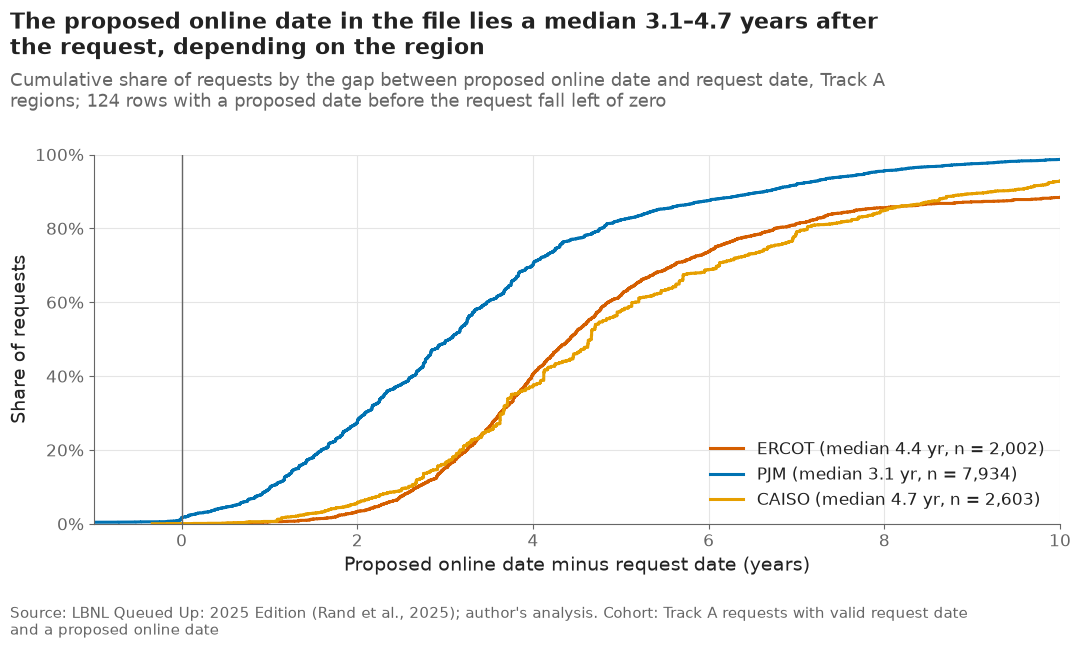

,count,mean,std,min,25%,50%,75%,max
region,,,,,,,,
CAISO,2603.0,5.32,2.83,-0.33,3.46,4.66,6.69,23.60
ERCOT,2002.0,8.80,12.38,0.32,3.46,4.42,6.08,49.32
PJM,7934.0,3.38,2.37,-26.04,1.84,3.05,4.30,17.95


In [21]:
amb = dated[in_region & dated["q_date_valid"] & dated["prop_date"].notna()]
amb_years = (amb["prop_date"] - amb["q_date"]).dt.days / config.DAYS_PER_YEAR
amb_medians = amb_years.groupby(amb["region"]).median()

fig, ax = plt.subplots()
for region in TRACK_A:
    x, y = ecdf(amb_years[amb["region"] == region])
    ax.step(x, y, where="post", color=plots.region_color(region),
            label=f"{region} (median {amb_medians[region]:.1f} yr, n = {len(x):,})")
ax.axvline(0, color=plots.MUTED, linewidth=1)
ax.set_xlim(-1, 10)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xlabel("Proposed online date minus request date (years)")
ax.set_ylabel("Share of requests")
ax.legend(loc="lower right")
plots.finish(fig,
             f"The proposed online date in the file lies a median {amb_medians.min():.1f}–"
             f"{amb_medians.max():.1f} years after the request, depending on the region",
             "Cumulative share of requests by the gap between proposed online date and request date, "
             f"Track A regions; {(amb_years < 0).sum():,} rows with a proposed date before the request "
             "fall left of zero",
             "Track A requests with valid request date and a proposed online date")
save(fig, "01_14_proposed_timeline",
     "Distribution of the gap between the proposed online date and the request date (years) in CAISO, "
     "ERCOT and PJM.")
plt.show()
amb_years.groupby(amb["region"]).describe().round(2)

**Reading this.** The stored proposed online date lies a median 3.05 years after the request in PJM, 4.42 in ERCOT and 4.66 in CAISO. The tails contain impossible values (ERCOT up to 49.3 years; PJM down to −26.0 years) that need a cleaning rule. More important is the next figure: the stored date does not look like the proposal made at entry, so the planned "ambition gap" feature may not be an entry-time feature at all.

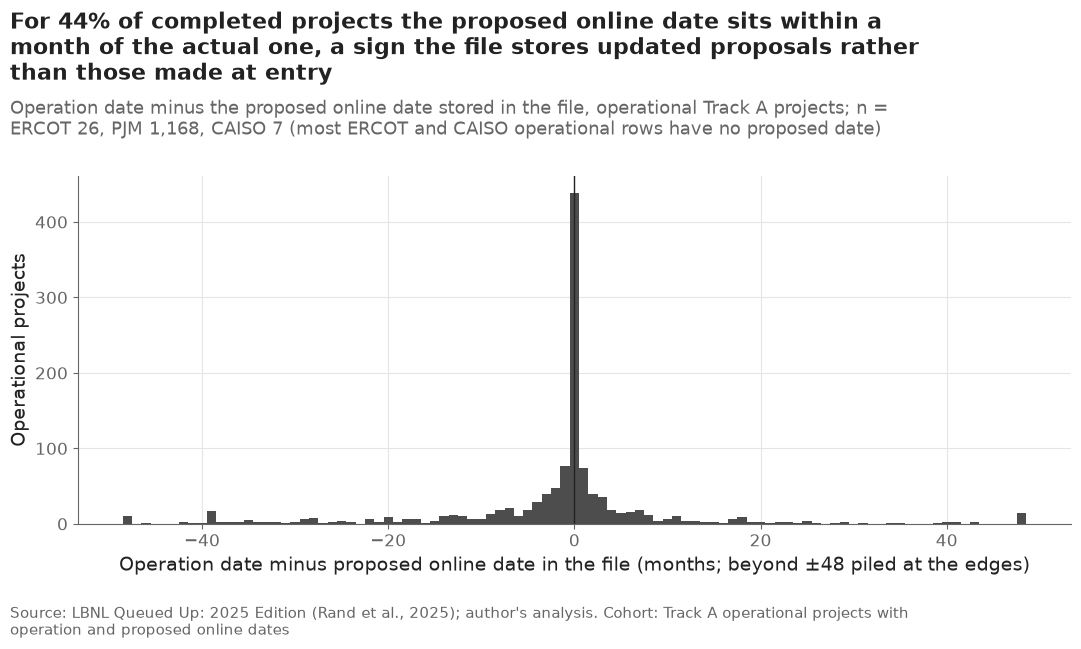

Operational rows with a proposed date, by region: {'CAISO': 0.032, 'ERCOT': 0.054, 'PJM': 0.999}


region,CAISO,ERCOT,PJM
share within ±1 month,0.286,0.769,0.434


In [22]:
operational = dated[in_region & (dated["q_status"] == "operational") & dated["on_date"].notna()]
built = operational[operational["prop_date"].notna()]
delay_months = (built["on_date"] - built["prop_date"]).dt.days / (config.DAYS_PER_YEAR / 12)
same_month = (delay_months.abs() <= 1).mean()

fig, ax = plt.subplots()
ax.hist(delay_months.clip(-48, 48), bins=np.arange(-48.5, 49.5, 1), color="#4D4D4D")
ax.axvline(0, color=plots.INK, linewidth=1)
ax.set_xlabel("Operation date minus proposed online date in the file (months; beyond ±48 piled at the edges)")
ax.set_ylabel("Operational projects")
n_by_region = built["region"].value_counts().reindex(TRACK_A).fillna(0).astype(int)
plots.finish(fig,
             f"For {same_month:.0%} of completed projects the proposed online date sits within a month "
             "of the actual one, a sign the file stores updated proposals rather than those made at entry",
             "Operation date minus the proposed online date stored in the file, operational Track A "
             "projects; n = " + ", ".join(f"{r} {n:,}" for r, n in n_by_region.items())
             + " (most ERCOT and CAISO operational rows have no proposed date)",
             "Track A operational projects with operation and proposed online dates")
save(fig, "01_15_proposed_vs_actual_online_date",
     "Months between the actual operation date and the proposed online date recorded in the LBNL file "
     "for completed projects in CAISO, ERCOT and PJM.")
plt.show()
print("Operational rows with a proposed date, by region:",
      (operational.groupby("region")["prop_date"].apply(lambda s: s.notna().mean())).round(3).to_dict())
(delay_months.groupby(built["region"]).apply(lambda s: (s.abs() <= 1).mean())).round(3).to_frame(
    "share within ±1 month").T

**Reading this.** For PJM, 43.4% of completed projects (n = 1,168) have a proposed online date within one month of their actual operation date; pooled over the three ISOs it is 44%. A proposal made years before completion would rarely land within a month of the real date, so the spike at zero suggests the queues overwrite the proposed date as a project advances. The coverage pattern points the same way: 99.9% of PJM's operational rows carry a proposed date but only 5.4% of ERCOT's and 3.2% of CAISO's, as if the field were cleared on completion there. ERCOT (n = 26) and CAISO (n = 7) are too small to read on their own. Consequence for notebook 04: `ambition_gap_years` built from this field risks leaking post-entry information. Unless an entry-time snapshot of the proposed date is available (for example from earlier LBNL releases), I would keep it out of the main models and test it only in the leakage ablation — **ASK ALAN**.

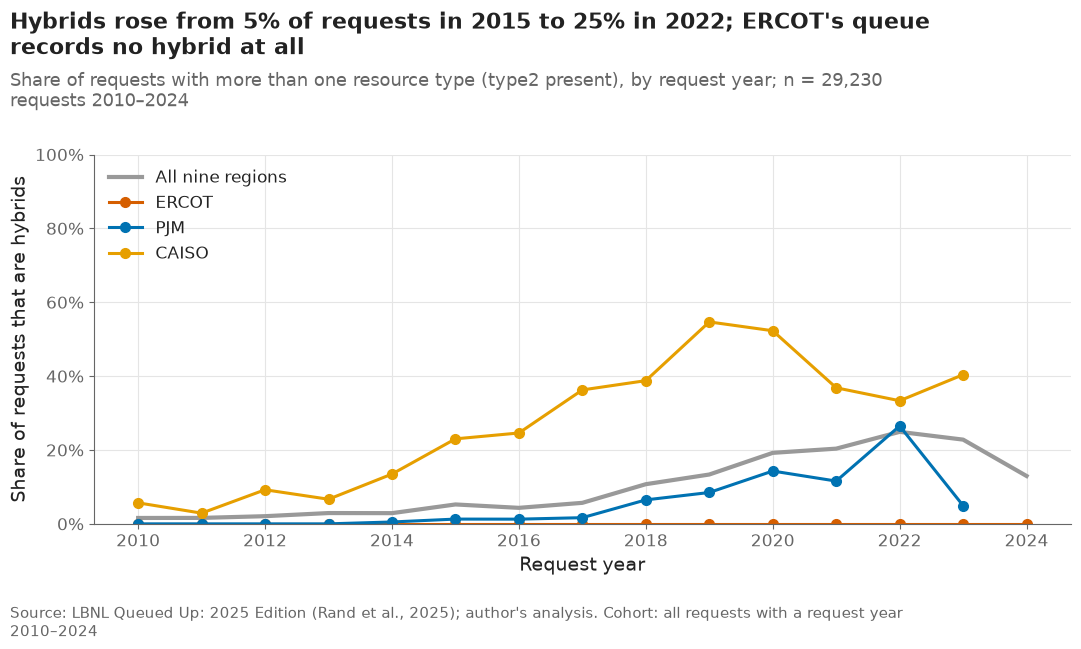

q_year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
CAISO,5.7,2.9,9.2,6.7,13.5,23.0,24.6,36.3,38.8,54.7,52.3,36.8,33.3,40.4,NaN
ERCOT,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ISO-NE,11.1,18.2,0.0,37.5,25.6,27.1,23.3,14.8,8.6,11.3,25.9,30.0,38.3,10.4,11.6
MISO,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.9,7.2,13.8,22.1,45.5,11.7
NYISO,0.0,11.1,6.2,28.6,0.0,2.4,0.0,0.0,1.9,0.6,6.1,13.8,10.4,9.6,9.8
PJM,0.0,0.0,0.0,0.0,0.5,1.3,1.3,1.7,6.5,8.5,14.3,11.6,26.5,4.9,NaN
SPP,0.0,0.0,0.0,4.7,0.0,0.0,0.0,0.4,0.7,3.8,17.5,19.1,4.3,14.0,7.3
Southeast,4.3,5.3,0.0,3.1,0.0,0.0,0.4,0.9,3.0,11.1,23.1,31.4,17.2,10.8,8.4
West,1.1,1.5,3.2,2.1,1.8,3.3,7.9,13.6,30.4,32.5,43.9,41.2,44.8,48.3,38.1
All,1.6,1.6,2.1,2.9,2.9,5.3,4.3,5.7,10.7,13.4,19.2,20.4,24.9,22.8,13.0


In [23]:
recent_years = range(2010, 2025)
hyb = dated[dated["q_year"].between(2010, 2024)].assign(hybrid=lambda t: t["type2"].notna())
hyb_region = hyb.groupby(["q_year", "region"])["hybrid"].mean().unstack().reindex(recent_years)
hyb_all = hyb.groupby("q_year")["hybrid"].mean().reindex(recent_years)

fig, ax = plt.subplots()
ax.plot(hyb_all.index, hyb_all.values, color=config.OTHER_REGION_COLOR, linewidth=3,
        label="All nine regions")
for region in TRACK_A:
    ax.plot(hyb_region.index, hyb_region[region], color=plots.region_color(region), marker="o",
            label=region)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xlabel("Request year")
ax.set_ylabel("Share of requests that are hybrids")
ax.legend(loc="upper left")
plots.finish(fig,
             f"Hybrids rose from {hyb_all[2015]:.0%} of requests in 2015 to {hyb_all.max():.0%} in "
             f"{hyb_all.idxmax()}; ERCOT's queue records no hybrid at all",
             "Share of requests with more than one resource type (type2 present), by request year; "
             f"n = {len(hyb):,} requests 2010–2024",
             "all requests with a request year 2010–2024")
save(fig, "01_16_hybrid_share",
     "Share of interconnection requests that combine more than one resource type, by request year, "
     "nationally and for CAISO, ERCOT and PJM.")
plt.show()
(100 * hyb_region.join(hyb_all.rename("All"))).round(1).T

**Reading this.** Hybrids rose from 5.3% of requests in 2015 to 24.9% in 2022 and fell back to 13.0% in 2024. CAISO peaked at 54.7% in 2019. ERCOT shows 0.0% in every year: its queue in the public file does not record hybrid composition, so the hybrid flag can only be learned from the other regions. In the region-stratified Cox model this is harmless; in pooled models it means the hybrid effect is estimated from CAISO and PJM.

## 4. EIA-860M through the EIA API (source S2)

The route metadata gives the latest month; `eia_api.pull_generators()` then
pages through it 5,000 rows at a time, saves each page as returned and the
combined table as parquet. If those files exist the cell reads them instead of
calling the API (the cache that makes a second run fast).

In [24]:
meta = eia_api.fetch_route_metadata(eia_key)
period = meta["end_period"]
generators, pull_log = eia_api.pull_generators(period, key=eia_key)

print("Route:", config.EIA_ROUTE)
print("Months served:", meta["start_period"], "to", period)
print("Pull:", pull_log)
print("Rows received equal the API total:", pull_log["rows"] == pull_log["total"])
print("Duplicate plant-generator keys:", int(generators.duplicated(["plantid", "generatorid"]).sum()))
generators["status"].value_counts().to_frame("generators")

Route: electricity/operating-generator-capacity
Months served: 2008-01 to 2026-07
Pull: {'period': '2026-07', 'total': 28324, 'rows': 28324, 'pages': 6, 'from_cache': True}
Rows received equal the API total: True
Duplicate plant-generator keys: 0


,generators
status,
OP,26072
SB,1497
OS,539
OA,216


In [25]:
fields = list(config.EIA_MIN_FIELD_SHARE)
filled = generators[fields].replace("", np.nan).notna()
field_share = pd.DataFrame({
    "all rows": filled.mean(),
    "status OP": filled[generators["status"] == "OP"].mean(),
    "required": pd.Series(config.EIA_MIN_FIELD_SHARE),
})
generators["type_clean"] = generators["technology"].map(
    lambda t: config.EIA_TECHNOLOGY_MAP.get(t, ("Other", ""))[0])
profile = {
    "period": period, "rows": pull_log["rows"], "total": pull_log["total"], "pages": pull_log["pages"],
    "status": {k: int(v) for k, v in generators["status"].value_counts().items()},
    "field_share_all": field_share["all rows"].round(4).to_dict(),
    "field_share_op": field_share["status OP"].round(4).to_dict(),
    "nameplate_gw": round(generators["nameplate-capacity-mw"].sum() / 1000, 1),
}
(paths.RESULTS / "eia860m_profile.json").write_text(json.dumps(profile, indent=2), encoding="utf-8")
field_share.round(4)

,all rows,status OP,required
operating-year-month,1.0,1.0,0.95
stateid,1.0,1.0,0.99
technology,1.0,1.0,0.99
county,1.0,1.0,0.95
latitude,1.0,1.0,0.95
longitude,1.0,1.0,0.95


In [26]:
state_gw = generators.pivot_table(index="stateid", columns="type_clean", values="nameplate-capacity-mw",
                                  aggfunc="sum", fill_value=0) / 1000
state_gw = state_gw.assign(total=state_gw.sum(axis=1)).sort_values("total", ascending=False)
state_gw.head(12).round(1)

type_clean,Battery,Coal,Gas,Geothermal,Hydro,Nuclear,Offshore Wind,Other,Solar,Wind,total
stateid,,,,,,,,,,,
TX,18.3,16.6,84.1,0.0,0.7,5.1,0.0,1.7,33.3,43.9,203.8
CA,16.3,0.1,40.2,2.9,13.7,2.3,0.0,1.9,25.5,6.5,109.4
FL,1.2,3.7,55.3,0.0,0.0,3.9,0.0,3.5,13.3,0.0,81.0
PA,0.0,5.2,29.9,0.0,2.4,10.5,0.0,2.3,1.2,1.7,53.3
IL,0.1,7.4,18.0,0.0,0.0,12.4,0.0,0.9,5.2,8.7,52.8
AZ,6.6,2.8,17.7,0.0,2.9,4.2,0.0,0.2,8.8,1.7,45.0
NY,0.3,0.0,24.2,0.0,5.9,3.4,0.1,4.4,3.2,2.9,44.4
GA,0.3,6.2,18.6,0.0,3.6,6.5,0.0,2.3,5.5,0.0,43.0
NC,0.3,4.4,19.3,0.0,2.0,5.4,0.0,1.1,7.1,0.4,40.0


**Reading this.** The API served months from 2008-01 to 2026-07. The 2026-07 pull returned 28,324 rows in 6 pages — exactly the total the API reported — with no duplicate plant-generator keys (this run read the cached pages; the first run called the API). Status: 26,072 operating, 1,497 standby, 539 out of service, 216 out of service but expected back. Every field the gate needs (operating month, state, technology, county, latitude, longitude) is 100% filled. Texas has the most operable capacity (203.8 GW), then California (109.4 GW).

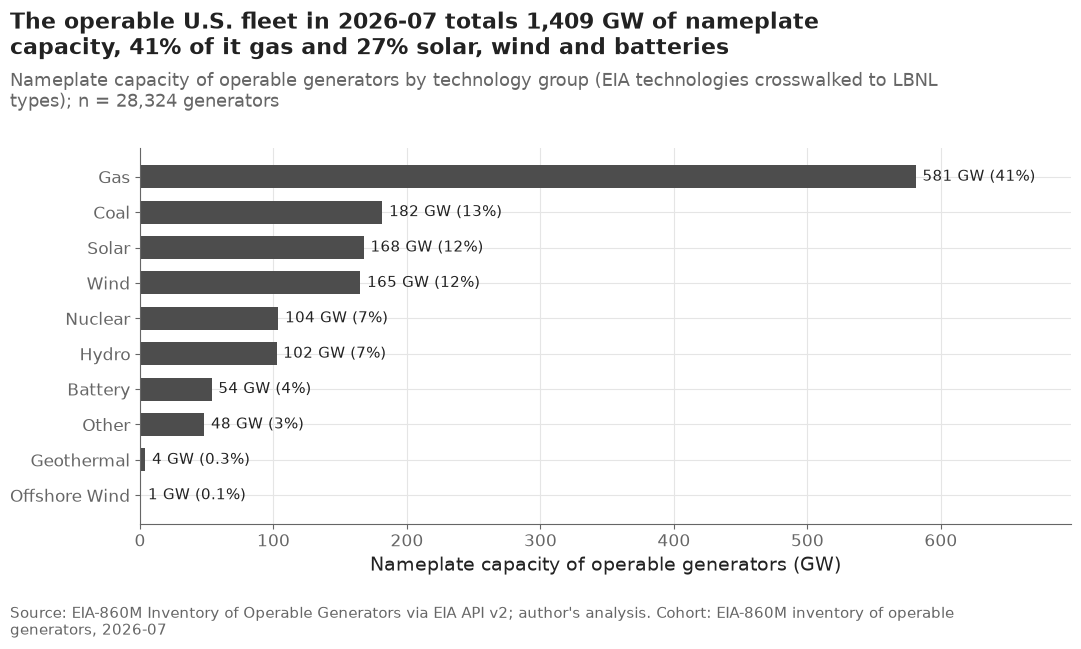

In [27]:
fleet = (generators.groupby("type_clean")["nameplate-capacity-mw"].sum() / 1000).sort_values()
total_gw = fleet.sum()

fig, ax = plt.subplots()
ax.barh(fleet.index, fleet.values, color="#4D4D4D", height=0.65)
for i, value in enumerate(fleet.values):
    share = f"{value / total_gw:.1%}" if value / total_gw < 0.01 else f"{value / total_gw:.0%}"
    ax.text(value + 5, i, f"{value:,.0f} GW ({share})", va="center", fontsize=11)
ax.set_xlabel("Nameplate capacity of operable generators (GW)")
ax.set_xlim(0, fleet.max() * 1.2)
plots.finish(fig,
             f"The operable U.S. fleet in {period} totals {total_gw:,.0f} GW of nameplate capacity, "
             f"{fleet['Gas'] / total_gw:.0%} of it gas and {fleet[['Solar', 'Wind', 'Battery']].sum() / total_gw:.0%} "
             "solar, wind and batteries",
             "Nameplate capacity of operable generators by technology group (EIA technologies crosswalked "
             f"to LBNL types); n = {len(generators):,} generators",
             f"EIA-860M inventory of operable generators, {period}", eia=True, lbnl=False)
save(fig, "01_17_eia_fleet_by_technology",
     "Nameplate capacity of all operable U.S. generators by technology group, from EIA-860M.")
plt.show()

**Reading this.** The operable fleet in 2026-07 has 1,409 GW of nameplate capacity: 41% gas, and 27% solar, wind and batteries together. Batteries are 53.7 GW — small next to the 245 GW of battery capacity requested in 2023 alone (01_04), which is the gap between the queue and what gets built in one number.

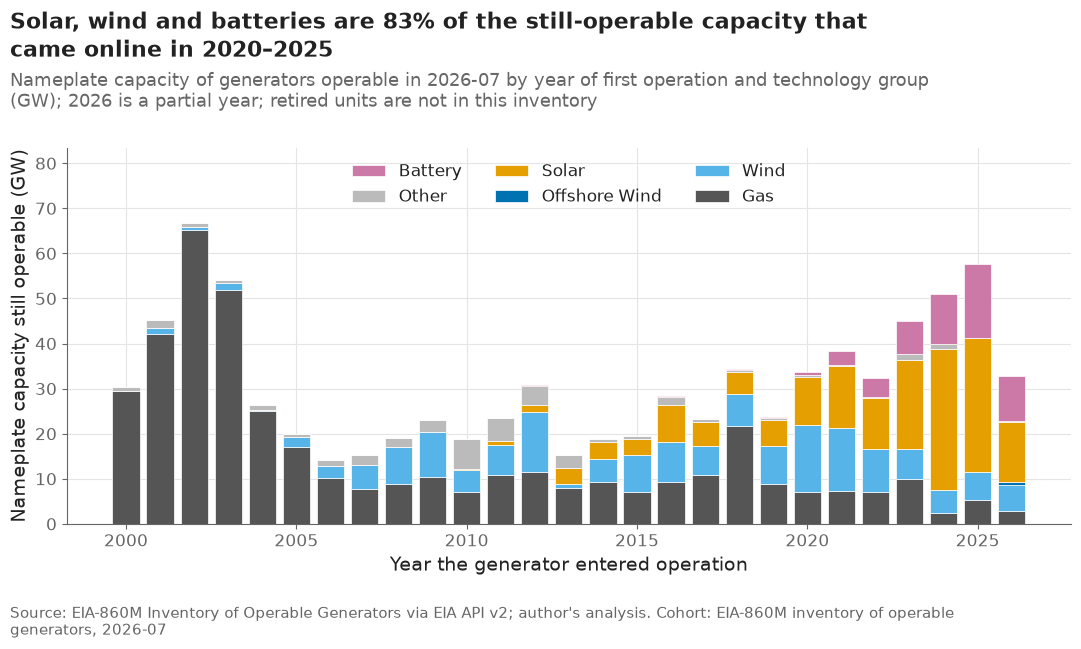

tech_group,Gas,Wind,Offshore Wind,Solar,Solar+Battery,Other,Battery
op_year,,,,,,,
2018,21.7,7.1,0.0,5.0,0.0,0.5,0.2
2019,8.8,8.5,0.0,5.9,0.0,0.4,0.2
2020,7.1,14.9,0.0,10.7,0.0,0.4,0.6
2021,7.4,13.8,0.0,13.8,0.0,0.2,3.1
2022,7.1,9.5,0.0,11.3,0.0,0.3,4.3
2023,9.9,6.6,0.0,19.8,0.0,1.4,7.2
2024,2.4,5.0,0.1,31.2,0.0,1.2,11.1
2025,5.3,6.3,0.0,29.6,0.0,0.2,16.4
2026,2.9,5.6,0.8,13.4,0.0,0.0,10.1


In [28]:
generators["op_year"] = generators["operating-year-month"].str[:4].astype(int)
generators["tech_group"] = generators["type_clean"].map(plots.tech_group)
add_years = range(2000, int(period[:4]) + 1)
added = (generators[generators["op_year"].between(2000, int(period[:4]))]
         .groupby(["op_year", "tech_group"])["nameplate-capacity-mw"].sum().unstack()
         .reindex(index=add_years, columns=stack_order).fillna(0) / 1000)

fig, ax = plt.subplots()
bottom = np.zeros(len(added))
present = [g for g in stack_order if added[g].sum() > 0]  # EIA has no hybrid category
for group in present:
    ax.bar(added.index, added[group], bottom=bottom, color=config.TECH_COLORS[group], width=0.8,
           label=group, edgecolor="white", linewidth=0.5)
    bottom += added[group].values
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="upper center", ncol=3)
ax.set_ylim(0, bottom.max() * 1.25)
ax.set_xlabel("Year the generator entered operation")
ax.set_ylabel("Nameplate capacity still operable (GW)")
window = added.loc[2020:2025]
clean = window[["Solar", "Wind", "Battery"]].sum().sum() / window.sum().sum()
plots.finish(fig,
             f"Solar, wind and batteries are {clean:.0%} of the still-operable capacity that came online "
             "in 2020–2025",
             f"Nameplate capacity of generators operable in {period} by year of first operation and "
             f"technology group (GW); {period[:4]} is a partial year; retired units are not in this inventory",
             f"EIA-860M inventory of operable generators, {period}", eia=True, lbnl=False)
save(fig, "01_18_eia_additions_by_year",
     "Nameplate capacity of still-operable generators by year of first operation and technology group, "
     "from EIA-860M.")
plt.show()
added.loc[2018:].round(1)

**Reading this.** In 2024, 31.2 GW of solar and 11.1 GW of batteries came online and are still operable; in 2025, 29.6 GW and 16.4 GW. Gas additions dropped to 2.4 GW in 2024. Because the inventory only holds generators that still exist, older years are understated (retired units are gone), so this figure is a picture of today's fleet by vintage, not a history of annual additions.

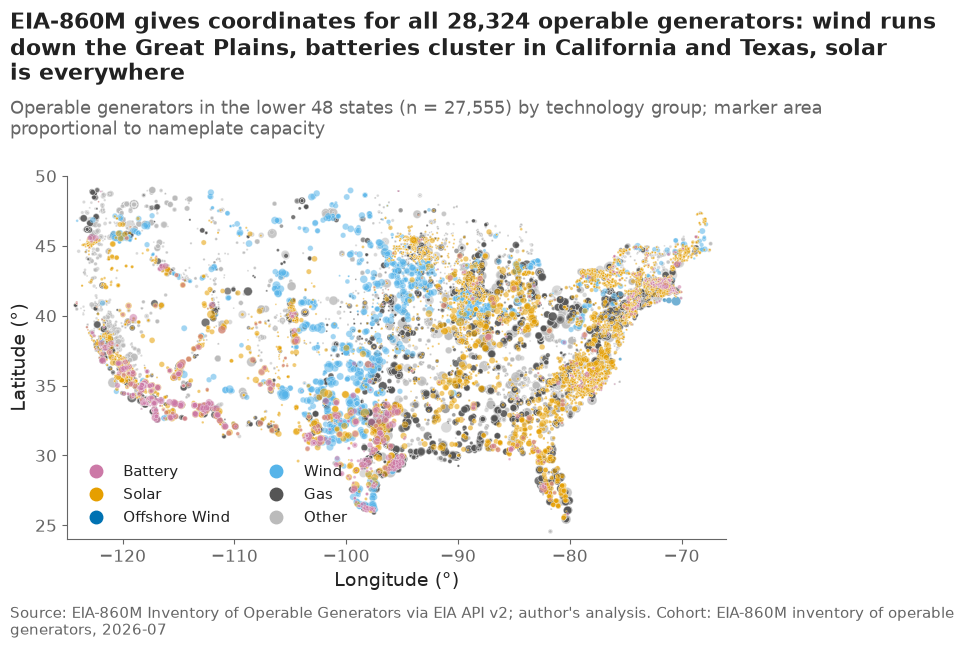

In [29]:
lower48 = generators[generators["longitude"].between(-125, -66) & generators["latitude"].between(24, 50)]
draw_order = ["Other", "Gas", "Wind", "Offshore Wind", "Solar", "Solar+Battery", "Battery"]

fig, ax = plt.subplots()
for group in draw_order:
    part = lower48[lower48["tech_group"] == group]
    ax.scatter(part["longitude"], part["latitude"], s=np.sqrt(part["nameplate-capacity-mw"].clip(lower=0)) * 1.6,
               color=config.TECH_COLORS[group], alpha=0.55, linewidths=0.3, edgecolors="white",
               rasterized=True)  # 27,000 points as vectors would make a 20 MB SVG
ax.set_aspect(1.25)
ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)
ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")
ax.grid(False)
ax.legend(handles=[Line2D([], [], marker="o", linestyle="", markersize=9, color=config.TECH_COLORS[g],
                          label=g) for g in draw_order[::-1] if (lower48["tech_group"] == g).any()],
          loc="lower left", ncol=2, fontsize=11)
plots.finish(fig,
             f"EIA-860M gives coordinates for all {len(generators):,} operable generators: wind runs down "
             "the Great Plains, batteries cluster in California and Texas, solar is everywhere",
             f"Operable generators in the lower 48 states (n = {len(lower48):,}) by technology group; "
             "marker area proportional to nameplate capacity",
             f"EIA-860M inventory of operable generators, {period}", eia=True, lbnl=False)
save(fig, "01_19_eia_generator_map",
     "Locations of operable generators in the lower 48 states from EIA-860M, colored by technology group "
     "and sized by nameplate capacity.")
plt.show()

**Reading this.** Every operable generator has coordinates and a county, which makes the stretch state map (F9) and county-level context possible. The pattern is read from the figure only: wind follows the Great Plains, batteries cluster in California and Texas, solar is spread across the country. No number in the report comes from this map.

## 5. Technology crosswalk (EIA technology → LBNL `type_clean`)

Every EIA technology is mapped to one of the plan's ten groups (Solar, Wind,
Offshore Wind, Battery, Gas, Hydro, Nuclear, Coal, Geothermal, Other) by the
dictionary in `src/config.py`; "Other" always carries a note. The table is
saved to `data/processed/technology_crosswalk.csv` and reviewed below.

In [30]:
crosswalk = eia_api.technology_crosswalk(generators)
crosswalk.to_csv(paths.DATA_PROCESSED / "technology_crosswalk.csv", index=False)
crosswalk_complete = bool(
    crosswalk["type_clean"].isin(config.CROSSWALK_TYPES).all()
    and not crosswalk["note"].str.startswith("NOT IN MAP").any()
    and (crosswalk.loc[crosswalk["type_clean"] == "Other", "note"] != "").all())
print("Every EIA technology mapped (Other always explained):", crosswalk_complete)
crosswalk.round(2)

Every EIA technology mapped (Other always explained): True


,eia_technology,type_clean,note,n_generators,nameplate_gw
0,Natural Gas Fired Combined Cycle,Gas,,1945,328.28
1,Conventional Steam Coal,Coal,,445,181.32
2,Solar Photovoltaic,Solar,,8254,166.26
3,Onshore Wind Turbine,Wind,,1571,165.18
4,Natural Gas Fired Combustion Turbine,Gas,,2257,161.12
5,Nuclear,Nuclear,,96,103.70
6,Natural Gas Steam Turbine,Gas,,550,83.88
7,Conventional Hydroelectric,Hydro,,3983,80.07
8,Batteries,Battery,,1120,53.71
9,Petroleum Liquids,Other,LBNL Oil and Diesel; folded into Other,3804,30.48


**Reading this.** All 27 EIA technologies map to one of the ten groups, and every "Other" carries a note (petroleum, biomass, waste and refinery gases, EIA's residual category). Two judgment calls are worth stating: pumped storage (22.22 GW) goes to Hydro, although LBNL files some pumped storage as "Other Storage", and petroleum liquids (30.48 GW) go to Other, as LBNL's Oil and Diesel types do in the linkage. The crosswalk is used only to compare the two sources; it does not change any LBNL field.

## 6. Quick linkage test (no modeling)

Can an LBNL project be found in EIA-860M? Tested where both sources have an
operation date: LBNL operational projects in ERCOT and PJM. The rule in
`src/linkage.py` (decision #11) matches on state, technology group, nameplate
within ±15% and a shared name word — **not** on dates — and then checks
whether the EIA operating month falls within six months of LBNL's
`on_date`. Notebook 10 (stretch) is worth doing only if ≥ 40% match and
≥ 80% of matches agree.

In [31]:
projects = dated[(dated["q_status"] == "operational") & dated["region"].isin(config.LINK_REGIONS)
                 & dated["on_date"].notna()]
vintages = linkage.eia_plant_vintages(generators)
matches = linkage.match_projects(projects, vintages)

keep = ["q_id", "entity", "region", "state", "project_name", "type1", "mw1", "on_date"]
projects[keep].join(matches.drop(columns="region")).to_csv(
    paths.DATA_PROCESSED / "linkage_test_matches.csv", index=False)

link_overall = linkage.summarise_matches(matches)
link_region = linkage.summarise_matches(matches, by="region")
link_type = linkage.summarise_matches(matches, by="link_type")
pd.concat([link_overall.assign(level="overall").rename(columns={"group": "value"}),
           link_region.assign(level="region").rename(columns={"region": "value"}),
           link_type.assign(level="technology").rename(columns={"link_type": "value"})]
          )[["level", "value", "projects", "matched", "match_rate", "agree", "agree_rate"]].to_csv(
    paths.RESULTS / "linkage_test.csv", index=False)

match_rate = float(link_overall["match_rate"].iloc[0])
agree_rate = float(link_overall["agree_rate"].iloc[0])
linkage_viable = match_rate >= config.LINK_MIN_MATCH_RATE and agree_rate >= config.LINK_MIN_AGREE_RATE
print(f"Projects tested: {len(projects):,}")
print(f"Matched: {pct(match_rate)}   agree within 6 months: {pct(agree_rate)}")
print("Notebook 10 viable:", linkage_viable)
pd.concat([link_region, link_type.rename(columns={"link_type": "region"})]).round(3)

Projects tested: 1,650
Matched: 31.1%   agree within 6 months: 74.9%
Notebook 10 viable: False


,region,projects,matched,match_rate,agree,agree_rate
0,ERCOT,481,229,0.476,165,0.721
1,PJM,1169,284,0.243,219,0.771
0,Battery,34,15,0.441,14,0.933
1,Coal,64,3,0.047,2,0.667
2,Gas,481,66,0.137,39,0.591
3,Hydro,32,5,0.156,1,0.200
4,Nuclear,45,0,0.000,0,NaN
5,Offshore Wind,1,0,0.000,0,NaN
6,Other,242,25,0.103,17,0.680
7,Solar,455,210,0.462,174,0.829


In [32]:
pd.crosstab(matches["link_type"], matches["reason"], margins=True)

reason,matched,"name found, capacity differs >15 %",no EIA plant of that type in the state,no EIA plant shares a name word,no usable project name,All
link_type,,,,,,
Battery,15,1,0,17,1,34
Coal,3,34,2,24,1,64
Gas,66,297,0,100,18,481
Hydro,5,25,0,1,1,32
Nuclear,0,43,0,1,1,45
Offshore Wind,0,0,0,0,1,1
Other,25,50,0,158,9,242
Solar,210,116,0,102,27,455
Wind,189,63,0,40,4,296


**Reading this.** Of 1,650 operational ERCOT and PJM projects, 31.1% matched an EIA plant and 74.9% of those matches agree on the operation month within six months. Both are below the plan's bars (40% and 80%), so **notebook 10 is dropped**, as the plan says it should be. The reason table shows where the rule fails: 629 projects have a same-type plant with a shared name but a capacity more than 15% different — 297 gas, 43 nuclear, 34 coal — which is what uprates and partial phases of existing plants look like; another 443 share no name word with any same-type plant in their state. By technology, wind (63.9%) and solar (46.2%) link best, and solar matches agree 82.9% of the time. A linkage aimed only at new solar, wind and battery projects might pass, but that would be a new test with its own pre-set bar, not a rescue of this one.

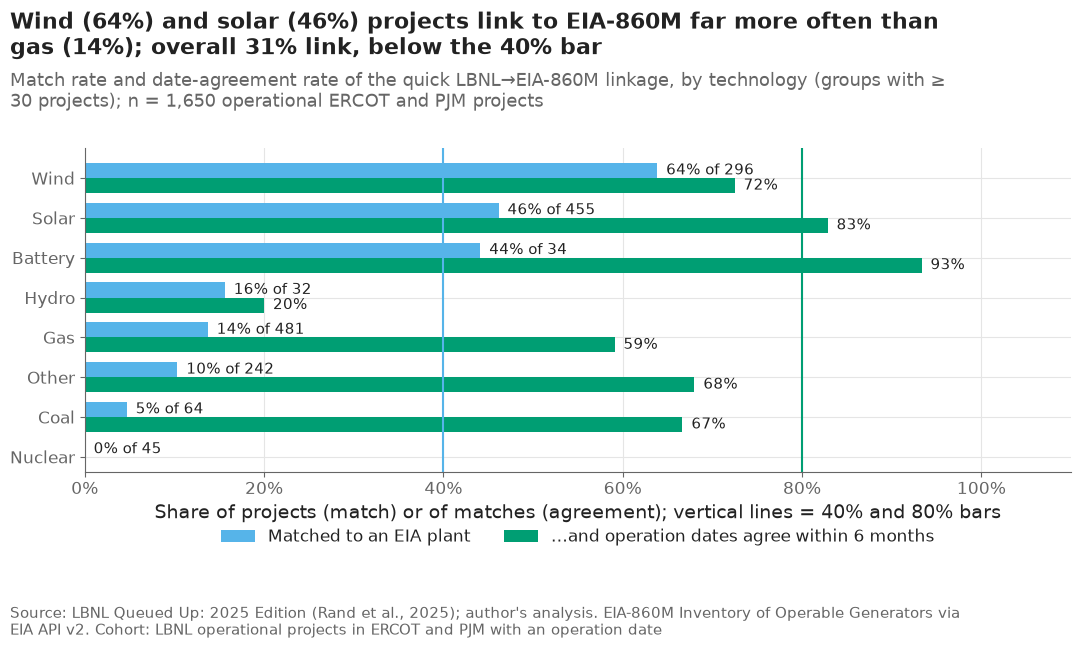

In [33]:
plot_types = link_type[link_type["projects"] >= 30].sort_values("match_rate")
width = 0.38
fig, ax = plt.subplots()
y = np.arange(len(plot_types))
for offset, column, color, label in [(width / 2, "match_rate", "#56B4E9", "Matched to an EIA plant"),
                                     (-width / 2, "agree_rate", config.OUTCOME_COLORS["operation"],
                                      "…and operation dates agree within 6 months")]:
    ax.barh(y + offset, plot_types[column], height=width, color=color, label=label)
for i, row in enumerate(plot_types.itertuples()):
    ax.text(row.match_rate + 0.01, i + width / 2, f"{row.match_rate:.0%} of {row.projects}",
            va="center", fontsize=11)
    ax.text(row.agree_rate + 0.01, i - width / 2, f"{row.agree_rate:.0%}", va="center", fontsize=11)
ax.axvline(config.LINK_MIN_MATCH_RATE, color="#56B4E9", linewidth=1.5)
ax.axvline(config.LINK_MIN_AGREE_RATE, color=config.OUTCOME_COLORS["operation"], linewidth=1.5)
ax.set_yticks(y, plot_types["link_type"])
ax.set_xlim(0, 1.1)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Share of projects (match) or of matches (agreement); vertical lines = 40% and 80% bars")
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.13))
rates = plot_types.set_index("link_type")["match_rate"]
plots.finish(fig,
             f"Wind ({rates['Wind']:.0%}) and solar ({rates['Solar']:.0%}) projects link to EIA-860M far "
             f"more often than gas ({rates['Gas']:.0%}); overall {match_rate:.0%} link, below the 40% bar",
             "Match rate and date-agreement rate of the quick LBNL→EIA-860M linkage, by technology "
             f"(groups with ≥ 30 projects); n = {len(projects):,} operational ERCOT and PJM projects",
             "LBNL operational projects in ERCOT and PJM with an operation date", eia=True)
save(fig, "01_20_linkage_by_technology",
     "Share of LBNL operational ERCOT/PJM projects matched to an EIA-860M plant, and share of matches "
     "whose operation dates agree within six months, by technology.")
plt.show()

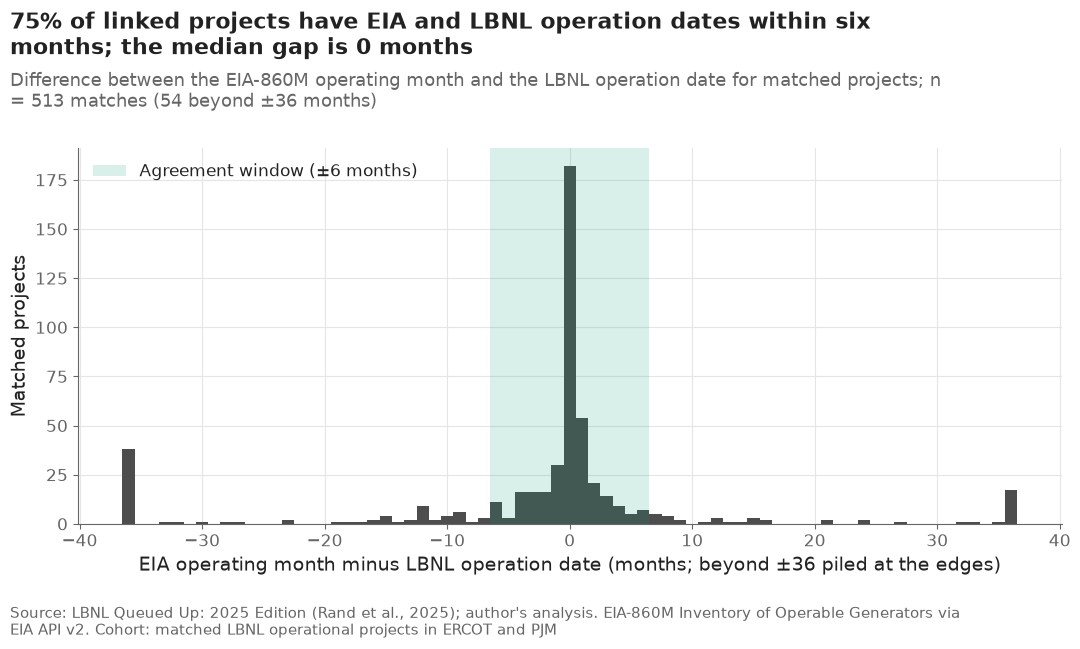

,count,mean,std,min,25%,50%,75%,max
months apart,513.0,-11.6,100.7,-1378.0,-2.0,0.0,1.0,606.0


In [34]:
gap = matches["months_apart"].dropna()
clipped = gap.clip(-36, 36)
fig, ax = plt.subplots()
ax.hist(clipped, bins=np.arange(-36.5, 37.5, 1), color="#4D4D4D")
ax.axvspan(-6.5, 6.5, color=config.OUTCOME_COLORS["operation"], alpha=0.15,
           label="Agreement window (±6 months)")
ax.set_xlabel("EIA operating month minus LBNL operation date (months; beyond ±36 piled at the edges)")
ax.set_ylabel("Matched projects")
ax.legend(loc="upper left")
plots.finish(fig,
             f"{agree_rate:.0%} of linked projects have EIA and LBNL operation dates within six months; "
             f"the median gap is {gap.median():.0f} months",
             "Difference between the EIA-860M operating month and the LBNL operation date for matched "
             f"projects; n = {len(gap):,} matches ({(gap.abs() > 36).sum()} beyond ±36 months)",
             "matched LBNL operational projects in ERCOT and PJM", eia=True)
save(fig, "01_21_linkage_date_gap",
     "Distribution of the gap between EIA-860M operating month and LBNL operation date for linked "
     "projects.")
plt.show()
gap.describe().round(1).to_frame("months apart").T

**Reading this.** The median gap between the EIA operating month and the LBNL operation date is 0 months and the middle half of matches lies between −2 and +1 months, so when the match is right, the two sources agree closely. The tails are long (from −1,378 to +606 months): those are matches to an older unit of the same plant — false or partial matches — and they are why agreement stops at 74.9%.

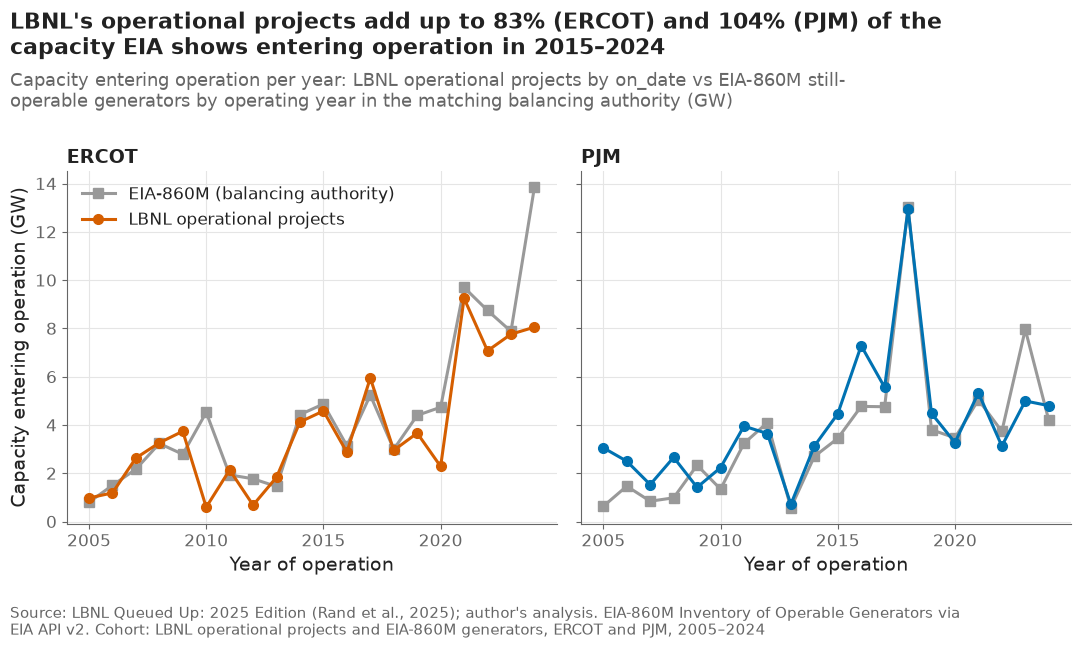

,ERCOT,PJM
"LBNL / EIA capacity, 2015–2024",0.83,1.038


In [35]:
ba_code = {"ERCOT": "ERCO", "PJM": "PJM"}
add_range = range(2005, 2025)
fig, axes = plt.subplots(1, 2, sharey=True)
coverage_ratio = {}
for ax, region in zip(axes, config.LINK_REGIONS):
    lbnl_part = dated[(dated["region"] == region) & (dated["q_status"] == "operational") & dated["on_date"].notna()]
    lbnl_gw = lbnl_part.groupby(lbnl_part["on_date"].dt.year)["mw"].sum().reindex(add_range).fillna(0) / 1000
    eia_part = generators[generators["balancing_authority_code"] == ba_code[region]]
    eia_gw = eia_part.groupby("op_year")["nameplate-capacity-mw"].sum().reindex(add_range).fillna(0) / 1000
    ax.plot(add_range, eia_gw, color=config.OTHER_REGION_COLOR, marker="s", label="EIA-860M (balancing authority)")
    ax.plot(add_range, lbnl_gw, color=plots.region_color(region), marker="o", label="LBNL operational projects")
    ax.set_title(region)
    ax.set_xlabel("Year of operation")
    year_ticks(ax, 2005, 2024)
    coverage_ratio[region] = lbnl_gw.loc[2015:2024].sum() / eia_gw.loc[2015:2024].sum()
axes[0].set_ylabel("Capacity entering operation (GW)")
axes[0].legend(loc="upper left")
plots.finish(fig,
             f"LBNL's operational projects add up to {coverage_ratio['ERCOT']:.0%} (ERCOT) and "
             f"{coverage_ratio['PJM']:.0%} (PJM) of the capacity EIA shows entering operation in 2015–2024",
             "Capacity entering operation per year: LBNL operational projects by on_date vs EIA-860M "
             "still-operable generators by operating year in the matching balancing authority (GW)",
             "LBNL operational projects and EIA-860M generators, ERCOT and PJM, 2005–2024", eia=True)
save(fig, "01_22_lbnl_vs_eia_additions",
     "Capacity entering operation per year according to LBNL operational projects and EIA-860M "
     "generators, ERCOT and PJM.")
plt.show()
pd.Series(coverage_ratio, name="LBNL / EIA capacity, 2015–2024").round(3).to_frame().T

**Reading this.** Summed over 2015–2024, LBNL's operational projects add up to 83% of the capacity EIA shows entering operation in ERCOT and 103.8% in PJM. PJM above 100% is expected: LBNL counts an uprate as new capacity on its completion date while EIA dates the original unit, and generators retired since then are not in the EIA inventory. ERCOT's shortfall is concentrated in 2024 in the figure; projects that came online late in 2024 may still show as active in the end-2024 LBNL snapshot. Overall, LBNL's "operational" status tracks real additions closely in these two ISOs, which supports using it as the outcome for Track A.

## 7. Data access statement and data dictionary

`data/README.md` holds the access statement (sources, terms, how to obtain
them, what is redistributed). This cell fills its dictionary section: every
column of both raw tables with its type, how often it is filled and its
meaning (LBNL's codebook; EIA's field list), plus the two derived tables.

In [36]:
def markdown_table(frame):
    """Render a small DataFrame as a GitHub markdown table."""
    header = "| " + " | ".join(frame.columns) + " |"
    rule = "|" + "|".join("---" for _ in frame.columns) + "|"
    body = ["| " + " | ".join(str(v) for v in row) + " |" for row in frame.itertuples(index=False)]
    return "\n".join([header, rule, *body])


lbnl_notes = dict(zip(codebook["field"], codebook["description"]))
lbnl_dict = pd.DataFrame({
    "column": raw.columns,
    "type": [str(t) for t in raw.dtypes],
    "filled": [pct(raw[c].notna().mean(), 0) for c in raw.columns],
    "meaning (LBNL codebook)": [lbnl_notes.get(c, "") for c in raw.columns],
})
lbnl_dict.loc[lbnl_dict["column"].isin(config.LBNL_DATE_COLS), "type"] = "Excel serial date"
eia_dict = pd.DataFrame({
    "column": generators.columns.drop(["type_clean", "op_year", "tech_group"]),
})
eia_dict["type"] = [str(generators[c].dtype) for c in eia_dict["column"]]
eia_dict["filled"] = [pct(generators[c].replace("", np.nan).notna().mean(), 0) for c in eia_dict["column"]]
eia_dict["meaning"] = eia_dict["column"].map(eia_api.FIELD_DESCRIPTIONS).fillna("")
derived = pd.DataFrame([
    {"table": "data/processed/technology_crosswalk.csv",
     "columns": "eia_technology, type_clean, note, n_generators, nameplate_gw",
     "made by": "notebook 01 §5"},
    {"table": "data/processed/linkage_test_matches.csv",
     "columns": ", ".join(keep) + ", link_type, matched, reason, eia_plantid, eia_plant_name, eia_mw, months_apart",
     "made by": "notebook 01 §6"},
])

dictionary = "\n\n".join([
    "## Data dictionary",
    "*This section is written by `notebooks/01_get_data.ipynb`; edit the notebook, not this text.*",
    f"### LBNL sheet `{config.LBNL_SHEET}` ({raw.shape[0]:,} rows × {raw.shape[1]} columns)",
    "Codebook fields absent from the public sheet: "
    + ", ".join(f"`{f}`" for f in sorted(set(codebook["field"]) - set(raw.columns))) + ".",
    markdown_table(lbnl_dict),
    f"### EIA-860M, route `{config.EIA_ROUTE}`, period {period} ({len(generators):,} rows)",
    markdown_table(eia_dict),
    "### Derived tables",
    markdown_table(derived),
])
readme_path = paths.DATA / "README.md"
readme = readme_path.read_text(encoding="utf-8")
readme = re.sub(r"(?s)<!-- dictionary:start -->.*<!-- dictionary:end -->",
                lambda _: f"<!-- dictionary:start -->\n{dictionary}\n<!-- dictionary:end -->", readme)
readme_path.write_text(readme, encoding="utf-8")
print("data/README.md dictionary updated:", len(lbnl_dict), "LBNL columns,", len(eia_dict), "EIA columns")
lbnl_dict.head(8)

data/README.md dictionary updated: 31 LBNL columns, 26 EIA columns


,column,type,filled,meaning (LBNL codebook)
0,q_id,object,100%,queue ID number
1,q_status,object,100%,"current queue status (active, withdrawn, suspe..."
2,q_date,Excel serial date,98%,interconnection request date (date project ent...
3,prop_date,Excel serial date,80%,proposed online date from interconnection appl...
4,on_date,Excel serial date,8%,date project became operational (if applicable)
5,wd_date,Excel serial date,28%,date project withdrawn from queue (if applicable)
6,ia_date,Excel serial date,7%,date of signed interconnection agreement (if a...
7,IA_status_raw,object,67%,interconnection study phase / status from queue


**Reading this.** The dictionary in `data/README.md` now lists all 31 LBNL columns with LBNL's own codebook wording and all 26 EIA columns, each with its type and how often it is filled, plus the two derived tables. It is regenerated on every run, so it cannot drift from the data.

## 8. Readiness checklist — the gate

Each line of PLAN.md §5.3 becomes a printed check with the number behind it.
Thresholds come from `src/config.py` and are applied strictly; a failure is
reported, not explained away. The outcome is GO only if every check passes.
The table goes to `results/readiness_checks.csv` and the report to
`docs/data_readiness.md`.

In [37]:
checks = []


def check(name, condition, observed, passed):
    """Record one readiness check."""
    checks.append({"check": name, "pass condition": condition, "observed": observed,
                   "result": "PASS" if passed else "FAIL"})


cov = coverage.set_index("region").loc[TRACK_A]
early_med, late_med = early.median(), late.median()
mock_ok = all(abs(mock_shares[r] - v) <= 0.01 for r, v in config.MOCKUP_EXPECTED.items())
headline_ok = (abs(op_share - config.HEADLINE_OPERATIONAL_SHARE) <= config.HEADLINE_TOLERANCE
               and abs(wd_share - config.HEADLINE_WITHDRAWN_SHARE) <= config.HEADLINE_TOLERANCE)
n_candidates = int(candidates.sum())
(paths.RESULTS / "headline_checks.json").write_text(json.dumps({
    "capacity_share_operational_2000_2019": round(float(op_share), 4),
    "capacity_share_withdrawn_2000_2019": round(float(wd_share), 4),
    "median_ir_to_cod_2000_2007": round(float(early_med), 3),
    "median_ir_to_cod_2018_2024": round(float(late_med), 3),
    "track_a_candidates": n_candidates,
    "track_a_candidates_valid_q_date": int((candidates & dated["q_date_valid"]).sum()),
    "test_cohort": held_out,
}, indent=2), encoding="utf-8")

check("S1 present, SHA-256 recorded, loads",
      "frozen file verified; 36,441 rows × 31 columns",
      f"SHA-256 match = {get_lbnl.sha256(lbnl_path) == config.LBNL_SHA256}; "
      f"{raw.shape[0]:,} × {raw.shape[1]}",
      get_lbnl.sha256(lbnl_path) == config.LBNL_SHA256 and raw.shape == (36441, 31))
check("S1 counts match the 2026-10-03 audit",
      "status, region, 204 placeholder q_date, 17 negative-MW rows",
      f"{int(audit_table['match'].sum())} of {len(audit_table)} items equal",
      bool(audit_table["match"].all()))
check("S1 headline: capacity outcome of 2000–2019 requests",
      "≈13% operational / ≈77% withdrawn (±1 point)",
      f"{pct(op_share)} / {pct(wd_share)}", headline_ok)
check("S1 headline: median request-to-operation time",
      "< 2 yr for 2000–07 completions; > 4 yr for 2018–24",
      f"{early_med:.2f} yr (n = {len(early)}) / {late_med:.2f} yr (n = {len(late)})",
      early_med < 2 and late_med > 4)
check("S1 naive mock-up reproduces",
      "5-yr completion CAISO 4% / ERCOT 21% / PJM 15% (±1 point)",
      " / ".join(f"{r} {pct(mock_shares[r])}" for r in ["CAISO", "ERCOT", "PJM"]), mock_ok)
check("S1 event-date coverage: operation dates",
      f"≥ {config.COVERAGE_MIN_ON_DATE:.0%} of operational rows have on_date in each Track A region",
      ", ".join(f"{r} {pct(cov.loc[r, 'on_date_share'])}" for r in TRACK_A),
      bool((cov["on_date_share"] >= config.COVERAGE_MIN_ON_DATE).all()))
check("S1 event-date coverage: withdrawal dates",
      f"≥ {config.COVERAGE_MIN_WD_DATE:.0%} of withdrawn rows have wd_date in each Track A region",
      ", ".join(f"{r} {pct(cov.loc[r, 'wd_date_share'])}" for r in TRACK_A),
      bool((cov["wd_date_share"] >= config.COVERAGE_MIN_WD_DATE).all()))
check("S1 Track A candidate sample",
      f"{config.TRACK_A_RANGE[0]:,}–{config.TRACK_A_RANGE[1]:,} projects",
      f"{n_candidates:,} (with a valid request date: {int((candidates & dated['q_date_valid']).sum()):,})",
      config.TRACK_A_RANGE[0] <= n_candidates <= config.TRACK_A_RANGE[1])
check("S1 enough events for a held-out test",
      f"2017–2019 Track A entrants ≥ {config.TEST_MIN_PROJECTS:,} with ≥ {config.TEST_MIN_COMPLETIONS} "
      "completions by end-2024",
      f"{held_out['projects']:,} projects; {held_out['completions']} completions; "
      f"{held_out['withdrawals']:,} withdrawals",
      held_out["projects"] >= config.TEST_MIN_PROJECTS
      and held_out["completions"] >= config.TEST_MIN_COMPLETIONS)
check("S2 API works with the key",
      f"metadata returns; latest period ≥ {config.EIA_MIN_PERIOD}; rows = response.total",
      f"latest {period}; {pull_log['rows']:,} rows of {pull_log['total']:,} in {pull_log['pages']} pages",
      period >= config.EIA_MIN_PERIOD and pull_log["rows"] == pull_log["total"])
field_ok = (field_share["status OP"]["operating-year-month"] >= config.EIA_MIN_FIELD_SHARE["operating-year-month"]
            and all(field_share["all rows"][f] >= v for f, v in config.EIA_MIN_FIELD_SHARE.items()
                    if f != "operating-year-month"))
check("S2 fields usable",
      "operating month ≥ 95% of OP rows; state, technology ≥ 99%; county, lat/long ≥ 95%",
      ", ".join(f"{f} {pct(field_share['all rows'][f])}" for f in fields), field_ok)
check("Crosswalk complete",
      "every EIA technology maps to one type, or to Other with a note",
      f"{len(crosswalk)} technologies; complete = {crosswalk_complete}", crosswalk_complete)
check("Linkage test",
      "match rate reported; notebook 10 viable if ≥ 40% matched and ≥ 80% of matches agree ±6 months",
      f"{pct(match_rate)} matched, {pct(agree_rate)} agree → notebook 10 "
      + ("viable" if linkage_viable else "not viable, dropped"), True)
readme_text = (paths.DATA / "README.md").read_text(encoding="utf-8")
licenses_ok = all(s in readme_text for s in ["### S1", "### S2", "**Terms:**", "**How to obtain:**",
                                              "What is redistributed"])
check("Licenses documented",
      "data/README.md gives source, terms, how to obtain, what is redistributed for S1 and S2",
      f"all sections present = {licenses_ok}", licenses_ok)

In [38]:
TEXT_SUFFIXES = {".py", ".md", ".ipynb", ".txt", ".json", ".csv", ".ini", ".toml", ".cfg", ".yml",
                 ".yaml", ".example", ""}
listed = subprocess.run(["git", "ls-files", "--cached", "--others", "--exclude-standard"],
                        cwd=paths.REPO, capture_output=True, text=True, check=True).stdout.splitlines()
env_ignored = subprocess.run(["git", "check-ignore", "-q", ".env"], cwd=paths.REPO).returncode == 0
key_files, assigned, mentions = 0, [], []
for name in listed:
    file = paths.REPO / name
    if file.suffix not in TEXT_SUFFIXES or not file.is_file():
        continue
    text = file.read_text(encoding="utf-8", errors="ignore")
    key_files += eia_key in text
    if "EIA_API_KEY" in text:
        mentions.append(name)
    if re.search(r"EIA_API_KEY=[A-Za-z0-9]{20,}", text):
        assigned.append(name)
secrets_ok = env_ignored and key_files == 0 and not assigned
print("Files that would be committed:", len(listed))
print("Files mentioning the variable name:", mentions)
check("Secrets safe",
      ".env git-ignored; the key appears in no committed file; no key assigned outside .env",
      f".env ignored = {env_ignored}; files containing the key = {key_files}; "
      f"key assignments = {len(assigned)}", secrets_ok)

readiness = pd.DataFrame(checks)
readiness.to_csv(paths.RESULTS / "readiness_checks.csv", index=False)
failed = readiness.loc[readiness["result"] == "FAIL", "check"].tolist()
outcome = "GO" if not failed else "NO-GO (failed: " + "; ".join(failed) + ")"
print(readiness["result"].value_counts().to_dict(), "→", outcome)
readiness

Files that would be committed: 143
Files mentioning the variable name: ['.env.example', 'data/README.md', 'notebooks/01_get_data.ipynb', 'src/eia_api.py']
{'PASS': 15} → GO


,check,pass condition,observed,result
0,"S1 present, SHA-256 recorded, loads","frozen file verified; 36,441 rows × 31 columns","SHA-256 match = True; 36,441 × 31",PASS
1,S1 counts match the 2026-10-03 audit,"status, region, 204 placeholder q_date, 17 neg...",18 of 18 items equal,PASS
2,S1 headline: capacity outcome of 2000–2019 req...,≈13% operational / ≈77% withdrawn (±1 point),12.6% / 76.9%,PASS
3,S1 headline: median request-to-operation time,< 2 yr for 2000–07 completions; > 4 yr for 201...,1.82 yr (n = 240) / 4.14 yr (n = 884),PASS
4,S1 naive mock-up reproduces,5-yr completion CAISO 4% / ERCOT 21% / PJM 15%...,CAISO 4.2% / ERCOT 21.3% / PJM 15.2%,PASS
5,S1 event-date coverage: operation dates,≥ 95% of operational rows have on_date in each...,"ERCOT 98.4%, PJM 97.8%, CAISO 95.2%",PASS
6,S1 event-date coverage: withdrawal dates,≥ 82% of withdrawn rows have wd_date in each T...,"ERCOT 100.0%, PJM 96.9%, CAISO 82.6%",PASS
7,S1 Track A candidate sample,"13,500–14,500 projects","13,733 (with a valid request date: 13,438)",PASS
8,S1 enough events for a held-out test,"2017–2019 Track A entrants ≥ 2,000 with ≥ 150 ...","2,292 projects; 304 completions; 1,358 withdra...",PASS
9,S2 API works with the key,metadata returns; latest period ≥ 2026-06; row...,"latest 2026-07; 28,324 rows of 28,324 in 6 pages",PASS


**Reading this.** All 15 checks pass, so the gate reads **GO**. Two of them pass only because Alan amended their thresholds after the first evaluation, which read NO-GO on exactly these two (decision #15): CAISO's withdrawal-date coverage is 82.6% (bar 83% → 82%; the 83% was the audit's rounded value), and the 2017–2019 test cohort has 2,292 projects (bar 2,500 → 2,000; only 2,313 Track A rows entered in those years) with 304 completions against the unchanged minimum of 150. The test cohort is therefore smaller than the plan assumed, which will widen the confidence intervals in notebook 08; the bootstrap intervals there will show by how much. The secrets check confirms the key appears in no file that would be committed.

In [39]:
cov_table = coverage.assign(
    on_date_share=lambda t: (100 * t["on_date_share"]).round(1),
    wd_date_share=lambda t: (100 * t["wd_date_share"]).round(1),
    q_date_share=lambda t: (100 * t["q_date_share"]).round(1),
)[["region", "n_projects", "n_operational", "on_date_share", "n_withdrawn", "wd_date_share", "q_date_share"]]
report = "\n\n".join([
    "# Data readiness report (Phase 0 gate)",
    f"*Written by `notebooks/01_get_data.ipynb` on {date.today().isoformat()}. "
    "Every number below was computed by that notebook; thresholds are in `src/config.py`.*",
    "## Sources",
    f"- **S1** LBNL Queued Up 2025 project file `{config.LBNL_FILENAME}`, sheet `{config.LBNL_SHEET}`, "
    f"{raw.shape[0]:,} × {raw.shape[1]}, SHA-256 `{config.LBNL_SHA256}`. Release check on the LBNL "
    f"page: {release['status']} {release['detail']}.",
    f"- **S2** EIA-860M via EIA API v2, route `{config.EIA_ROUTE}`, period {period}: "
    f"{pull_log['rows']:,} generators in {pull_log['pages']} pages.",
    "## Checks",
    markdown_table(readiness),
    "**Threshold changes.** Two thresholds were amended by Alan after the first evaluation, which "
    "had read NO-GO on exactly these two checks (decision #15): withdrawal-date coverage in each "
    "Track A region ≥ 83% → ≥ 82%, and the held-out test cohort ≥ 2,500 → ≥ 2,000 projects "
    "(≥ 150 completions unchanged).",
    "## Event-date coverage by region (%)",
    markdown_table(cov_table),
    "## Notes for the next notebooks",
    f"- Track A candidates: {n_candidates:,}; with a valid request date {int((candidates & dated['q_date_valid']).sum()):,} "
    "(notebook 04 needs the request date, so its sample will be the smaller number before cleaning).",
    f"- Rows above 5,000 MW: {counts['mw_over_5000_rows']} (largest {counts['max_mw']:,.0f} MW); "
    f"missing q_year: {counts['missing_q_year']}; duplicate (q_id, entity) rows: {counts['duplicate_key_rows']}.",
    f"- Linkage: {pct(match_rate)} of ERCOT/PJM operational projects matched an EIA plant and "
    f"{pct(agree_rate)} of matches agree on the operation month within six months.",
    f"**Outcome ({date.today().isoformat()}): {outcome}**",
])
(paths.DOCS / "data_readiness.md").write_text(report + "\n", encoding="utf-8")
print(report.splitlines()[-1])

**Outcome (2026-10-03): GO**


## Takeaways

- The public LBNL file reproduces the 2026-10-03 audit exactly (18 of 18 items) and LBNL's headlines: 12.6% of 2000–2019 capacity built and 76.9% withdrawn; median wait from request to operation up from 1.82 to 4.14 years.
- Only CAISO, ERCOT and PJM record both exit dates, giving 13,733 Track A candidates (13,438 with a valid request date). The naive five-year completion share is 4.2% in CAISO, 15.2% in PJM and 21.3% in ERCOT.
- The EIA API works with the key: 28,324 operable generators for 2026-07, every needed field complete, all 27 technologies crosswalked.
- The quick linkage reaches 31.1% matched and 74.9% date agreement, below the 40% / 80% bars, so stretch notebook 10 is dropped; most failures are uprates or phases whose capacity differs from the EIA unit.
- A new risk for notebook 04: the stored proposed online date looks updated after entry (44% of completed projects within a month of their actual date), so the planned ambition-gap feature may leak.
- **Gate: GO.** All 15 checks pass after Alan amended two thresholds that the data could not meet as first written (decision #15): withdrawal-date coverage ≥ 82% (CAISO 82.6%) and ≥ 2,000 test projects (2,292, with 304 completions).

**What goes to the report:** 01_02 (why three ISOs: the data section), 01_06 (headline reproduced), 01_09 (the naive baseline the models must beat), 01_08 (regional waits, for the lender discussion) and 01_15 (a data limitation); the data access paragraph comes from `data/README.md`.